# Ideal 3-SAT QAOA + Amplitude Amplification
## 10 variables / 8 clauses · 1000 shots · local Sparrow comparison

本 Notebook 是**不含纠错的小规模算法实验**，不是原论文的随机 8-SAT 容错资源复现。
主实例固定 $n=10,m=8$；所有 QAOA、AA 和 Sparrow 使用同一个 CNF。
QAOA 的初态、phaser、mixer 沿用论文 Eqs. (2)–(5) / Fig. 1B；AA 对应 Eq. (6) / Fig. 1D，并明确补入完整状态制备 $A=U_{\rm QAOA}H^{\otimes n}$。

运行顺序：**实例与解 → 直接 SAT 成本与相位电路 → QAOA pretrain → 固定轮数 AA → 输出概率与 amplitude spectrum → 1000-shot 统计 → 耗时与 crossover**。

- 全部实验直接使用原始 SAT 子句构建相位电路，保留三次失败函数；不做二次降阶。QAOA 使用 10 个数据比特，SAT oracle 的工作 flags 在使用后反计算归零。
- QAOA 和固定 AA 各采样 **1000 shots**；成功概率曲线每个整数 $R$ 也独立采样 1000 shots。
- “准确度”指返回满足全部子句的解的比例；多解 SAT 不要求与 Sparrow 输出同一个字符串。
- 实测图是本机**经典态矢量模拟器 vs Sparrow 进程**。另提供明确假设的无纠错门时间模型；没有真实量子硬件计时，不能据此声称量子优势。

来源：[Omanakuttan et al., arXiv:2504.01897v1](https://arxiv.org/abs/2504.01897v1)，
[Brassard et al., amplitude amplification](https://arxiv.org/abs/quant-ph/0005055)，
[Sparrow 源码](https://github.com/adrianopolus/Sparrow)。

### 与论文的对应范围

成本、初态、相位器和 mixer 遵循 v1 式 (2)–(5)，主要说明统一使用 $H_C$、$H_M$。本地 3-SAT 的 n=10、m=8、参数优化器、固定 AA 整数轮数和 CPU 计时均为本地实验设置。论文主实验研究随机 8-SAT 的容错资源，二者不混为同一次实验。固定 AA 保持本项目设定，完整初态制备与反射的处理在第 5 节单独说明。


In [1]:
# 使用安装了 requirements.txt 的 Python 内核。当前验证环境为 phys1007。
from pathlib import Path
import csv, html, json, sys, platform, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from scipy.optimize import minimize
import qiskit, scipy

PROJECT = Path.cwd()
if PROJECT.name == 'notebooks': PROJECT = PROJECT.parent
elif (PROJECT/'qaoa_aa_3sat').is_dir(): PROJECT = PROJECT/'qaoa_aa_3sat'
elif (PROJECT/'simulation/qaoa_aa_3sat').is_dir(): PROJECT = PROJECT/'simulation/qaoa_aa_3sat'
elif not (PROJECT/'notebooks/QAOA_AA_3SAT_No_QEC.ipynb').is_file():
    candidate = Path('D:/桌面/hkust/urop/code/qaoa_aa_3sat')
    if candidate.is_dir(): PROJECT = candidate
FIGURES = PROJECT/'results/figures'
TABLES = PROJECT/'results/data'
INPUTS = PROJECT/'data'
for directory in [FIGURES,TABLES,INPUTS]: directory.mkdir(parents=True,exist_ok=True)

# 用户确认的主实例；这里集中设置所有可调参数。
N = 10
M = 8
INSTANCE_SEED = 20261014
TRAIN_SEED = 2410
SHOT_SEED = 5109
P_VALUES = [1,2,3]
P_SELECTED = 2
RESTARTS = 3
MAXITER = 100
SHOTS = 1000
SPARROW_RUNS = 1000
SPARROW_MAXFLIPS = 1_000_000
AA_R_MAX = 12
TARGET_SUCCESS = 0.99

# Crossover 的横轴要变化；主实例仍为 10/8。小规模扫 n，维持 m/n≈0.8。
SWEEP_N = [6,8,10,12]
SWEEP_INSTANCES = 3
SWEEP_SPARROW_RUNS = 500
TIMING_REPEATS = 5
# 仅用于“假设的无纠错门模型”，不是论文数值或硬件校准。
SINGLE_QUBIT_S = 50e-9
CX_S = 300e-9
MEASURE_S = 1e-6
RESET_S = 1e-6

plt.rcParams.update({'figure.dpi':115,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
COLORS = {'QAOA':'#245b8b','QAOA+AA':'#c96d2e','Sparrow':'#52615e'}
def save_figure(fig,name):
    fig.savefig(FIGURES/f'{name}.png',dpi=170,bbox_inches='tight')
    fig.savefig(FIGURES/f'{name}.pdf',bbox_inches='tight')
    display(fig); plt.close(fig)
def write_csv(filename,rows):
    rows=list(rows)
    if not rows: return
    with (TABLES/filename).open('w',newline='',encoding='utf-8-sig') as f:
        writer=csv.DictWriter(f,fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)
def show_table(rows,limit=None):
    rows=list(rows)
    if limit is not None: rows=rows[:limit]
    if not rows: return
    keys=list(rows[0])
    text='<table><thead><tr>'+''.join(f'<th>{html.escape(str(k))}</th>' for k in keys)+'</tr></thead><tbody>'
    for row in rows:
        text+='<tr>'+''.join(f'<td>{html.escape(str(row[k]))}</td>' for k in keys)+'</tr>'
    display(HTML(text+'</tbody></table>'))
print('Python',sys.version.split()[0], '| Qiskit',qiskit.__version__, '| SciPy',scipy.__version__)
print('Outputs:',PROJECT)
assert P_SELECTED in P_VALUES and SHOTS == 1000

Python 3.14.2 | Qiskit 2.3.0 | SciPy 1.17.0
Outputs: D:\桌面\hkust\urop\code\qaoa_aa_3sat


## 1. SAT 表示与经典求解器接口

`[(i, True), (j, False), ...]` 表示零起始编号的正/负文字。CNF 文件则使用一开始的整数编号。下面直接给出 Sparrow 接口源码，Notebook 不需要导入自写模块。

In [2]:
"""Run the installed Sparrow 2014 SAT solver on the same CNF as QAOA.

Source: https://github.com/adrianopolus/Sparrow
Installed upstream commit: fcbda5127ad873ec306905b5c22cc4388d079f17.

Sparrow is an incomplete local-search solver: failure within a budget means
UNKNOWN, never a proof of UNSAT. ``wall_time_s`` measures subprocess creation,
the native solver, and IPC/output decoding. CNF preparation and model validation
are outside this timer. For tiny instances, process creation can dominate;
the solver's own CPU-time statistic is rounded to 0.001 s and can be zero.
These timings do not establish a physical quantum/classical crossover.

All returned records use ordinary Python values and can be written to JSON.
The solver model is ordered [x_0, ..., x_(n-1)]. Its display bitstring reverses
this order to match Qiskit's |x_(n-1)...x_0> convention.
"""

from __future__ import annotations

import math
import operator
import os
from pathlib import Path
import re
import statistics
import subprocess
import tempfile
import time
from typing import Iterable, Sequence


DEFAULT_SPARROW_EXE = Path(
    "D:/桌面/hkust/urop/code/classical_solvers/sparrow/bin/sparrow.exe"
)
_MAX_NATIVE_INT = 2_147_483_647


def find_sparrow(project_root: str | Path | None = None) -> Path:
    """Locate Sparrow using SPARROW_EXE, nearby code folders, or this PC's path.

    ``project_root`` can be the experiment directory or the user's code folder.
    A configured SPARROW_EXE that does not exist is an error, not a silent
    fallback to another executable.
    """
    configured = os.environ.get("SPARROW_EXE")
    if configured:
        candidate = Path(configured).expanduser().resolve()
        if not candidate.is_file():
            raise FileNotFoundError(f"SPARROW_EXE does not exist: {candidate}")
        return candidate

    starts = [Path(project_root)] if project_root is not None else []
    module_file = globals().get('__file__')
    if module_file:
        starts.append(Path(module_file).resolve().parent)
    starts.append(Path.cwd())
    candidates: list[Path] = []
    for start in starts:
        start = start.expanduser().resolve()
        for parent in [start, *start.parents]:
            filename = "sparrow.exe" if os.name == "nt" else "sparrow"
            candidates.extend([
                parent / "classical_solvers" / "sparrow" / "bin" / filename,
                parent / "code" / "classical_solvers" / "sparrow" / "bin" / filename,
            ])
    if os.name == "nt":
        candidates.append(DEFAULT_SPARROW_EXE)
    seen: set[Path] = set()
    for candidate in candidates:
        if candidate not in seen and candidate.is_file():
            return candidate.resolve()
        seen.add(candidate)
    raise FileNotFoundError(
        "Sparrow was not found. Set SPARROW_EXE or pass exe_path to run_sparrow. "
        "On macOS first run classical_solvers/sparrow/build.sh."
    )


def _native_integer(value: int, name: str, minimum: int = 1) -> int:
    try:
        if isinstance(value, bool):
            raise TypeError
        number = operator.index(value)
    except TypeError as exc:
        raise TypeError(f"{name} must be an integer.") from exc
    if not minimum <= number <= _MAX_NATIVE_INT:
        raise ValueError(f"{name} must be in [{minimum}, {_MAX_NATIVE_INT}].")
    return int(number)


def _normalize_clauses(
    n: int, clauses: Iterable[Sequence[tuple[int, bool]]]
) -> tuple[int, list[list[tuple[int, bool]]]]:
    n = _native_integer(n, "n")
    normalized: list[list[tuple[int, bool]]] = []
    for j, clause in enumerate(clauses):
        literals: list[tuple[int, bool]] = []
        seen: set[int] = set()
        for literal in clause:
            if len(literal) != 2:
                raise ValueError(f"Clause {j} contains an invalid literal: {literal!r}")
            i, positive = literal
            i = _native_integer(i, "zero-based variable index", minimum=0)
            if i >= n:
                raise ValueError(f"Variable index {i} is outside 0 <= i < {n}.")
            if positive not in (True, False):
                raise ValueError("A literal's sign must be True (x_i) or False (NOT x_i).")
            if i in seen:
                raise ValueError(
                    f"Clause {j} repeats variable {i}; simplify repeated literals "
                    "and tautologies before running the native solver."
                )
            seen.add(i)
            literals.append((i, bool(positive)))
        if not literals:
            raise ValueError("An empty clause is UNSAT and must not be sent to Sparrow.")
        normalized.append(literals)
    if not normalized:
        raise ValueError("An empty formula is trivially SAT and must not be sent to Sparrow.")
    return n, normalized


def dimacs_from_clauses(
    n: int, clauses: Iterable[Sequence[tuple[int, bool]]]
) -> str:
    """Encode zero-based (variable, positive_literal) pairs as DIMACS CNF."""
    n, clauses = _normalize_clauses(n, clauses)
    lines = ["c Shared CNF for Sparrow and QAOA", f"p cnf {n} {len(clauses)}"]
    for clause in clauses:
        lines.append(" ".join(str(i + 1 if positive else -(i + 1))
                              for i, positive in clause) + " 0")
    return "\n".join(lines) + "\n"


def check_model(
    n: int, clauses: Iterable[Sequence[tuple[int, bool]]], model: Sequence[int]
) -> bool:
    """Independently evaluate all clauses on [x_0, ..., x_(n-1)]."""
    if len(model) != n or any(bit not in (0, 1) for bit in model):
        return False
    return all(any(bool(model[i]) == bool(positive) for i, positive in clause)
               for clause in clauses)


def _parse_model(stdout: str, n: int) -> list[int]:
    assignment: dict[int, int] = {}
    for line in stdout.splitlines():
        if not re.match(r"^\s*v(?:\s|$)", line):
            continue
        for token in line.strip().split()[1:]:
            literal = int(token)
            if literal == 0:
                break
            i = abs(literal) - 1
            bit = int(literal > 0)
            if i < 0 or i >= n:
                raise RuntimeError(f"Sparrow returned an out-of-range literal: {literal}")
            if i in assignment and assignment[i] != bit:
                raise RuntimeError("Sparrow returned inconsistent values for one variable.")
            assignment[i] = bit
    if len(assignment) != n:
        raise RuntimeError(f"Sparrow's SAT model is incomplete ({len(assignment)} / {n} variables).")
    return [assignment[i] for i in range(n)]


def _statistic(text: str, label: str, integer: bool = False) -> float | int | None:
    match = re.search(rf"^\s*c\s+{re.escape(label)}\s*:\s*([-+0-9.eE]+)",
                      text, flags=re.MULTILINE)
    if not match:
        return None
    value = float(match.group(1))
    if not math.isfinite(value):
        return None
    return int(value) if integer else value


def _text(value: str | bytes | None) -> str:
    return value.decode("utf-8", errors="replace") if isinstance(value, bytes) else (value or "")


def _ascii_temp_directory() -> Path:
    """The unmodified C input parser uses narrow filenames on Windows."""
    candidates = [os.environ.get("TMP"), os.environ.get("TEMP"), tempfile.gettempdir()]
    for name in candidates:
        if name:
            candidate = Path(name).resolve()
            if candidate.is_dir() and str(candidate).isascii():
                return candidate
    raise RuntimeError(
        "Sparrow needs a writable ASCII temporary path. Set TEMP to an existing "
        "ASCII-only folder; the original CNF and executable may have Chinese paths."
    )


def run_sparrow(
    n: int,
    clauses: Iterable[Sequence[tuple[int, bool]]],
    seed: int = 1,
    exe_path: str | Path | None = None,
    maxflips: int = 1_000_000,
    wall_timeout_s: float = 5.0,
    cpu_timeout_s: int | None = None,
) -> dict:
    """One native run, with an independently checked model and honest timing.

    Literal convention: ``[(0, True), (1, False), (2, True)]`` represents
    x_0 OR NOT x_1 OR x_2. ``status`` is SAT or UNKNOWN; ``termination_reason``
    distinguishes a verified SAT model, native search-budget exhaustion, and
    the external wall-time cap. Unexpected native exit codes raise an error.
    Native --runs is fixed at 1 so a seed identifies one solver trial.
    """
    n, clauses = _normalize_clauses(n, clauses)
    seed = _native_integer(seed, "seed", minimum=0)
    maxflips = _native_integer(maxflips, "maxflips")
    if not math.isfinite(wall_timeout_s) or wall_timeout_s <= 0:
        raise ValueError("wall_timeout_s must be a positive finite number.")
    if cpu_timeout_s is not None:
        cpu_timeout_s = _native_integer(cpu_timeout_s, "cpu_timeout_s")
    executable = find_sparrow() if exe_path is None else Path(exe_path).expanduser().resolve()
    if not executable.is_file():
        raise FileNotFoundError(f"Sparrow executable does not exist: {executable}")

    cnf_text = dimacs_from_clauses(n, clauses)
    temp_path: Path | None = None
    try:
        with tempfile.NamedTemporaryFile(
            mode="w", encoding="ascii", newline="\n", suffix=".cnf",
            prefix="sparrow_qaoa_", dir=_ascii_temp_directory(), delete=False,
        ) as temporary:
            temporary.write(cnf_text)
            temp_path = Path(temporary.name)
        command = [str(executable), "--randomc", "1", "-a", "--runs", "1",
                   "--maxflips", str(maxflips)]
        if cpu_timeout_s is not None:
            command.extend(["--timeout", str(cpu_timeout_s)])
        command.extend([str(temp_path), str(seed)])

        timed_out = False
        start = time.perf_counter_ns()
        try:
            completed = subprocess.run(
                command, capture_output=True, text=True, encoding="utf-8",
                errors="replace", timeout=float(wall_timeout_s), check=False,
            )
            stdout, stderr, exit_code = completed.stdout, completed.stderr, completed.returncode
        except subprocess.TimeoutExpired as exc:
            # subprocess.run kills and waits for the native process on timeout.
            stdout, stderr, exit_code = _text(exc.stdout), _text(exc.stderr), None
            timed_out = True
        wall_time_s = (time.perf_counter_ns() - start) * 1e-9
    finally:
        if temp_path is not None:
            temp_path.unlink(missing_ok=True)

    combined = stdout + "\n" + stderr
    if not timed_out and exit_code not in (0, 10):
        raise RuntimeError(
            f"Sparrow failed with native exit code {exit_code}.\n{combined[-4000:]}"
        )
    if re.search(r"^\s*(?:c\s+)?ERROR\b", combined, flags=re.MULTILINE):
        raise RuntimeError(f"Sparrow reported an internal/input error.\n{combined[-4000:]}")

    sat_claim = bool(re.search(r"^\s*s\s+SATISFIABLE\s*$", stdout, flags=re.MULTILINE))
    model: list[int] | None = None
    model_valid: bool | None = None
    if sat_claim:
        model = _parse_model(stdout, n)
        model_valid = check_model(n, clauses, model)
        if not model_valid:
            raise RuntimeError("Sparrow claimed SAT but the independent CNF check failed.")
        if not timed_out and exit_code != 10:
            raise RuntimeError("Sparrow printed SAT but did not use its documented exit code 10.")
    elif exit_code == 10:
        raise RuntimeError("Sparrow used SAT exit code 10 but did not print a SAT status/model.")

    status = "SAT" if model_valid else "UNKNOWN"
    reason = "verified_model" if model_valid else ("wall_time_limit" if timed_out else "native_search_budget")
    cpu_time_s = _statistic(combined, "Total CPU Time")
    total_flips = _statistic(combined, "totalFlips", integer=True)
    return {
        "solver": "Sparrow 2014 (Windows portability build)",
        "seed": seed, "n": n, "m": len(clauses), "status": status,
        "model": model,
        "model_bitstring": "".join(str(bit) for bit in reversed(model)) if model is not None else None,
        "model_int": sum(bit << i for i, bit in enumerate(model)) if model is not None else None,
        "model_valid": model_valid,
        "wall_time_s": wall_time_s, "cpu_time_s": cpu_time_s,
        "cpu_time_resolution_s": 0.001,
        "total_flips": total_flips, "exit_code": exit_code,
        "timed_out": timed_out, "termination_reason": reason,
        "maxflips": maxflips, "wall_timeout_s": float(wall_timeout_s),
        "cpu_timeout_s": cpu_timeout_s,
        "timer_scope": "subprocess creation + native solver + IPC/output decoding; excludes CNF preparation/model check",
        "exe_path": str(executable), "stdout": stdout, "stderr": stderr,
    }


def wilson_interval(successes: int, trials: int, z: float = 1.959963984540054) -> tuple[float, float]:
    """Two-sided Wilson score interval (95% by default) for a binomial rate."""
    if trials <= 0 or not 0 <= successes <= trials:
        raise ValueError("Require trials > 0 and 0 <= successes <= trials.")
    rate = successes / trials
    denominator = 1 + z * z / trials
    center = (rate + z * z / (2 * trials)) / denominator
    half_width = z * math.sqrt(rate * (1 - rate) / trials + z * z / (4 * trials * trials)) / denominator
    return max(0.0, center - half_width), min(1.0, center + half_width)


def run_sparrow_batch(
    n: int,
    clauses: Iterable[Sequence[tuple[int, bool]]],
    seeds: Iterable[int] = (1, 2, 3, 4, 5),
    exe_path: str | Path | None = None,
    **run_options,
) -> dict:
    """Independent seeded trials and empirical model-finding success fraction.

    This rate is comparable to 'a returned assignment satisfies every clause'.
    It is not a SAT/UNSAT decision-classification accuracy. Small batches have
    wide uncertainty, which is retained in the Wilson interval.
    """
    n, clauses = _normalize_clauses(n, clauses)
    seeds = list(seeds)
    if not seeds:
        raise ValueError("At least one seed is required.")
    executable = find_sparrow() if exe_path is None else Path(exe_path)
    results = [run_sparrow(n, clauses, seed=seed, exe_path=executable, **run_options)
               for seed in seeds]
    num_sat = sum(result["status"] == "SAT" for result in results)
    wall_times = [result["wall_time_s"] for result in results]
    cpu_times = [result["cpu_time_s"] for result in results if result["cpu_time_s"] is not None]
    return {
        "results": results, "seeds": [result["seed"] for result in results],
        "num_runs": len(results), "num_sat": num_sat,
        "success_rate": num_sat / len(results),
        "success_rate_95pct_wilson": list(wilson_interval(num_sat, len(results))),
        "median_wall_time_s": statistics.median(wall_times),
        "mean_wall_time_s": statistics.mean(wall_times),
        "std_wall_time_s": statistics.stdev(wall_times) if len(wall_times) > 1 else 0.0,
        "median_cpu_time_s": statistics.median(cpu_times) if cpu_times else None,
        "accuracy_definition": "fraction of trials returning an independently verified satisfying assignment",
        "timing_note": "Measured subprocess wall time; tiny N is often dominated by process creation. No physical quantum crossover is inferred.",
    }

## 2. 理想电路与可验证的态矢量实现

下面集中给出电路源码。训练使用 NumPy 加速的同一个酉演化，输出的固定电路状态由 Qiskit 实际生成；后面逐项验证它们相同。

In [3]:
"""Ideal SAT QAOA and amplitude amplification; no fault-tolerant compilation."""
import math
import time
import numpy as np
from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import DiagonalGate
from qiskit.quantum_info import Statevector


def sat_truth_table(n, clauses):
    states = np.arange(1 << n, dtype=np.int64)
    violations = np.zeros(1 << n, dtype=np.int64)
    for clause in clauses:
        unsat = np.ones(1 << n, dtype=bool)
        for i, positive in clause:
            bit = ((states >> i) & 1).astype(bool)
            unsat &= ~bit if positive else bit
        violations += unsat
    return violations, violations == 0


def paper_cost_diagonal(n, clauses):
    """Diagonal of the paper's H_C = -sum_j C_j, Eq. (4).

    Evaluate satisfied clauses directly. The violation count remains only a
    diagnostic; it is not a second Hamiltonian or the optimizer's objective.
    """
    states = np.arange(1 << n, dtype=np.int64)
    cost_diagonal = np.zeros(1 << n, dtype=np.int64)
    for clause in clauses:
        satisfied = np.zeros(1 << n, dtype=bool)
        for i, positive in clause:
            bit = ((states >> i) & 1).astype(bool)
            satisfied |= bit if positive else ~bit
        cost_diagonal -= satisfied
    return cost_diagonal


def generate_sat_instance(n, m, seed):
    """Uniform random distinct-variable 3-CNF, rejection conditioned on SAT.

    m is fixed, unlike the paper's large-n random-8-SAT ensemble. Exhaustive
    SAT checking is used only as a small-instance reference and simulation aid.
    """
    if n < 3 or m < 1:
        raise ValueError('Need n >= 3, m >= 1.')
    rng = np.random.default_rng(seed)
    for attempt in range(10000):
        clauses = []
        for _ in range(m):
            idx = rng.choice(n, 3, replace=False)
            signs = rng.integers(0, 2, size=3)
            clauses.append([(int(i), bool(s)) for i, s in zip(idx, signs)])
        violations, good = sat_truth_table(n, clauses)
        if good.any():
            return clauses, violations, good, attempt + 1
    raise RuntimeError('No satisfiable instance generated; change seed/density.')


def bitstring(k, n):
    return format(int(k), f'0{n}b')  # |x_(n-1)...x_0>, matching Qiskit.


def display_clause(clause):
    return '(' + ' OR '.join(('' if positive else 'NOT ') + f'x{i+1}'
                            for i, positive in clause) + ')'


def greedy_clause_colors(clauses):
    """A valid greedy coloring, not a claim of minimum chromatic number."""
    batches = []
    used = []
    for j, clause in enumerate(clauses):
        variables = {i for i, _ in clause}
        for b, occupied in enumerate(used):
            if not variables & occupied:
                batches[b].append(j)
                occupied.update(variables)
                break
        else:
            batches.append([j]); used.append(set(variables))
    return batches


def phaser_circuit(n, clauses, gamma):
    qc = QuantumCircuit(n, name='phaser')
    for batch in greedy_clause_colors(clauses):
        for j in batch:
            clause = clauses[j]
            positive = [i for i, sign in clause if sign]
            variables = [i for i, _ in clause]
            if positive: qc.x(positive)
            # Paper Eq. (4): H_C = -#SAT = #UNSAT-m; mark failure with -gamma.
            qc.mcp(-float(gamma), variables[:-1], variables[-1])
            if positive: qc.x(positive)
    # e^{-i gamma H_C} = e^{+i gamma m} e^{-i gamma #UNSAT}.
    qc.global_phase += float(gamma) * len(clauses)
    return qc


def mixer_circuit(n, beta):
    qc = QuantumCircuit(n, name='mixer')
    qc.rx(float(beta), range(n))  # H_M = (1/2) sum X, paper Eq. (3).
    return qc


def qaoa_circuit(n, clauses, gammas, betas, boxed=False):
    qc = QuantumCircuit(n, name='A=U H')
    qc.h(range(n))
    for layer, (gamma, beta) in enumerate(zip(gammas, betas), start=1):
        ph = phaser_circuit(n, clauses, gamma)
        mix = mixer_circuit(n, beta)
        if boxed:
            qc.append(ph.to_gate(label=f'phaser {layer}: gamma={gamma:.3f}'), range(n))
            qc.append(mix.to_gate(label=f'mixer {layer}: beta={beta:.3f}'), range(n))
        else:
            qc.compose(ph, inplace=True)
            qc.compose(mix, inplace=True)
    return qc


def zero_oracle(n):
    """O0 = I - 2 |0...0><0...0|. H on last wire converts MCX to MCZ."""
    qc = QuantumCircuit(n, name='O_0')
    qc.x(range(n))
    if n == 1:
        qc.z(0)
    else:
        qc.h(n-1); qc.mcx(list(range(n-1)), n-1); qc.h(n-1)
    qc.x(range(n))
    return qc


def clause_or_xor(qc, clause, flag):
    positive = [i for i, sign in clause if sign]
    if positive: qc.x(positive)
    qc.mcx([i for i, _ in clause], flag)
    if positive: qc.x(positive)
    qc.x(flag)  # flag <- flag XOR OR(literals).


def sat_oracle_with_flags(n, clauses, boxed=False):
    """Compute all clause flags, phase flip their AND, uncompute flags.

    Uses n+m qubits, m clean ancillas, and no error correction. The returned
    circuit is phase-equivalent to the diagonal simulator oracle when flags
    start in |0...0>. In the simulator we keep only the n data qubits.
    """
    m = len(clauses)
    qc = QuantumCircuit(n+m, name='O_C: SAT')
    compute = QuantumCircuit(n+m, name='compute C_j')
    for batch in greedy_clause_colors(clauses):
        for j in batch: clause_or_xor(compute, clauses[j], n+j)
    if boxed: qc.append(compute.to_gate(label='compute all clause flags'), range(n+m))
    else: qc.compose(compute, inplace=True)
    if m == 1: qc.z(n)
    else:
        qc.h(n+m-1); qc.mcx(list(range(n, n+m-1)), n+m-1); qc.h(n+m-1)
    if boxed: qc.append(compute.inverse().to_gate(label='uncompute flags'), range(n+m))
    else: qc.compose(compute.inverse(), inplace=True)
    return qc


def aa_circuit(n, clauses, gammas, betas, good, rounds, boxed=False):
    """Start A|0>, then repeat A O0 A† OC (global sign relative to BHMT)."""
    A = qaoa_circuit(n, clauses, gammas, betas)
    O0 = zero_oracle(n)
    OC = DiagonalGate(np.where(good, -1.0, 1.0).astype(complex))
    qc = QuantumCircuit(n, name=f'QAOA+AA R={rounds}')
    if boxed: qc.append(A.to_gate(label='A: H + trained QAOA'), range(n))
    else: qc.compose(A, inplace=True)
    for _ in range(int(rounds)):
        qc.append(OC, range(n))
        if boxed:
            qc.append(A.inverse().to_gate(label='A dagger'), range(n))
            qc.append(O0.to_gate(label='O_0'), range(n))
            qc.append(A.to_gate(label='A'), range(n))
        else:
            qc.compose(A.inverse(), inplace=True)
            qc.compose(O0, inplace=True)
            qc.compose(A, inplace=True)
    return qc


def qaoa_state(n, cost_diagonal, gammas, betas):
    """Fast exact NumPy evolution, independently checked against Qiskit.

    Use the complete H_C diagonal from paper Eq. (4), including its constant
    phase. Its complex amplitudes are checked directly against Qiskit.
    """
    state = np.full(1 << n, 1 / np.sqrt(1 << n), dtype=complex)
    for gamma, beta in zip(gammas, betas):
        state *= np.exp(-1j * gamma * cost_diagonal)
        co, si = np.cos(beta/2), -1j*np.sin(beta/2)
        for q in range(n):
            block = state.reshape(-1, 2, 1 << q)
            lo, hi = block[:, 0, :].copy(), block[:, 1, :].copy()
            block[:, 0, :] = co*lo + si*hi
            block[:, 1, :] = si*lo + co*hi
    return state


def train_qaoa(n, cost_diagonal, good, p, seed, restarts=3, maxiter=100, warm=None):
    rng = np.random.default_rng(seed)
    history = []
    attempts = []
    initial_points = []
    if warm is not None:
        old_p = len(warm['gammas'])
        initial_points.append(np.r_[warm['gammas'], np.zeros(p-old_p),
                                    warm['betas'], np.zeros(p-old_p)])
    while len(initial_points) < restarts:
        initial_points.append(np.r_[-rng.uniform(0, 2*np.pi, p),
                                    rng.uniform(-np.pi, np.pi, p)])
    def objective(params):
        state = qaoa_state(n, cost_diagonal, params[:p], params[p:])
        probabilities = np.abs(state)**2
        loss = float(probabilities @ cost_diagonal)
        history.append((len(history)+1, loss, float(probabilities[good].sum())))
        return loss
    start = time.perf_counter()
    best = None
    for initial in initial_points:
        # Preserve initial candidate, so warm-start nesting cannot worsen cost.
        loss0 = objective(initial)
        result = minimize(objective, initial, method='L-BFGS-B',
                          options={'maxiter': maxiter, 'ftol': 1e-10, 'maxls': 30})
        chosen = result.x if result.fun <= loss0 else initial
        loss = min(float(result.fun), loss0)
        attempts.append({'loss': loss, 'converged': bool(result.success),
                         'message': str(result.message), 'nfev': int(result.nfev)})
        if best is None or loss < best[0]: best = (loss, chosen.copy())
    train_time = time.perf_counter()-start
    gammas, betas = best[1][:p], best[1][p:]
    state = qaoa_state(n, cost_diagonal, gammas, betas)
    return {'p':p, 'gammas':gammas, 'betas':betas, 'state':state,
            'expected_cost':best[0], 'success':float(np.abs(state[good]) @ np.abs(state[good])),
            'train_time_s':train_time, 'nfev':len(history),
            'history':np.asarray(history), 'attempts':attempts}


def amplify(state, good, rounds):
    """Exact rank-one reflection equivalent to A O0 A† OC; no dense matrix."""
    psi = np.asarray(state, dtype=complex)
    current = psi.copy()
    for _ in range(int(rounds)):
        current[good] *= -1
        current -= 2 * psi * np.vdot(psi, current)
    return current


def aa_probability(success, rounds):
    theta = np.arcsin(np.sqrt(np.clip(success, 0, 1)))
    return np.sin((2*np.asarray(rounds)+1)*theta)**2


def choose_rounds(success):
    if success <= 0: raise ValueError('AA cannot amplify zero initial success.')
    if success >= 1: return {'paper_continuous':np.pi/4, 'paper_floor':0, 'best_first_peak':0}
    theta = np.arcsin(np.sqrt(success))
    continuous = np.pi/(4*theta)-0.5
    candidates = {0, max(0, int(np.floor(continuous))), max(0, int(np.ceil(continuous)))}
    optimal = max(sorted(candidates), key=lambda r: (float(aa_probability(success,r)), -r))
    paper = np.pi/(4*np.sqrt(success))
    return {'paper_continuous':float(paper), 'paper_floor':int(np.floor(paper)),
            'best_first_peak':optimal}


def sample_state(state, shots, rng):
    probabilities = np.abs(state)**2
    probabilities /= probabilities.sum()
    return rng.multinomial(int(shots), probabilities)


def repetitions_for_target(success, target=0.99):
    if success <= 0: return np.inf
    if success >= 1: return 1
    return max(1,int(np.ceil(np.log1p(-target)/np.log1p(-success))))


def one_shot_simulator_time(circuit, good, rng, repeats=7):
    # Rebuild the state for EVERY timed shot; no reuse of a 1000-shot state.
    durations = []
    for _ in range(repeats):
        start = time.perf_counter()
        state = Statevector.from_instruction(circuit)
        probability = state.probabilities()
        outcome = int(rng.choice(len(probability),p=probability/probability.sum()))
        valid = bool(good[outcome])
        durations.append(time.perf_counter()-start)
    return float(np.median(durations))


def ideal_gate_duration(circuit, one_qubit_s=50e-9, cx_s=300e-9):
    """Illustrative non-FT gate model, all-to-all, ASAP scheduling.

    Counts decomposed unitary gates including oracle ancillas. It is not a
    hardware measurement and not the paper's surface-code timing formula.
    """
    # These reusable modules can receive nonzero or superposed inputs.
    compiled = transpile(circuit, basis_gates=['x','h','rx','rz','cx'],
                         optimization_level=0, qubits_initially_zero=False)
    available = np.zeros(compiled.num_qubits)
    for instruction in compiled.data:
        if instruction.operation.name == 'barrier': continue
        qubits = [compiled.find_bit(q).index for q in instruction.qubits]
        if not qubits: continue
        duration = cx_s if instruction.operation.name == 'cx' else one_qubit_s
        end = float(max(available[qubits])) + duration
        available[qubits] = end
    return float(available.max()), {str(k):int(v) for k,v in compiled.count_ops().items()}


def non_ft_time_model(n, clauses, gammas, betas, rounds,
                      one_qubit_s=50e-9, cx_s=300e-9, measure_s=1e-6, reset_s=1e-6):
    A = qaoa_circuit(n,clauses,gammas,betas)
    tA, opsA = ideal_gate_duration(A,one_qubit_s,cx_s)
    t0, ops0 = ideal_gate_duration(zero_oracle(n),one_qubit_s,cx_s)
    tC, opsC = ideal_gate_duration(sat_oracle_with_flags(n,clauses),one_qubit_s,cx_s)
    per_shot = reset_s+tA+rounds*(2*tA+t0+tC)+measure_s
    return {'T_A_s':tA,'T_O0_s':t0,'T_OC_s':tC,'T_one_shot_s':per_shot,
            'ops_A':opsA,'ops_O0':ops0,'ops_OC':opsC,'oracle_qubits':n+len(clauses)}


def observed_crossings(x, quantum, classical):
    """Log-linear interpolation only INSIDE sampled intervals; no extrapolation."""
    x, q, c = np.asarray(x),np.asarray(quantum),np.asarray(classical)
    delta = np.log(q/c)
    roots = []
    for i in range(len(x)-1):
        if delta[i] == 0: roots.append(float(x[i]))
        elif delta[i]*delta[i+1] < 0:
            roots.append(float(x[i]+(x[i+1]-x[i])*(-delta[i])/(delta[i+1]-delta[i])))
    if delta[-1] == 0: roots.append(float(x[-1]))
    return roots

In [4]:
clauses, violations, good, generation_attempts = generate_sat_instance(N,M,INSTANCE_SEED)
cost_diagonal = paper_cost_diagonal(N, clauses)
assert np.array_equal(cost_diagonal, violations-M)
assert np.array_equal(good, cost_diagonal == -M)
SPARROW_EXE = find_sparrow(PROJECT)
cnf_path = INPUTS/f'instance_n{N}_m{M}_seed{INSTANCE_SEED}.cnf'
cnf_path.write_text(dimacs_from_clauses(N,clauses),encoding='ascii')
print(f'n={N}, m={M}, k=3; SAT solutions={good.sum()}/{1<<N}; uniform P={good.mean():.6f}')
print('Sparrow:',SPARROW_EXE)
for j,clause in enumerate(clauses,1): print(f'C{j} = {display_clause(clause)}')
print('Greedy clause batches:', [[j+1 for j in batch] for batch in greedy_clause_colors(clauses)])
print('Reference SAT states (first 12):',[bitstring(x,N) for x in np.flatnonzero(good)[:12]])
write_csv('cnf_clauses.csv',[{'clause':j+1,'literals':display_clause(c)} for j,c in enumerate(clauses)])

n=10, m=8, k=3; SAT solutions=408/1024; uniform P=0.398438
Sparrow: D:\桌面\hkust\urop\code\classical_solvers\sparrow\bin\sparrow.exe
C1 = (NOT x10 OR x6 OR x8)
C2 = (x5 OR NOT x4 OR x6)
C3 = (NOT x10 OR x5 OR x9)
C4 = (NOT x4 OR NOT x2 OR x6)
C5 = (x6 OR x1 OR x4)
C6 = (x8 OR NOT x9 OR NOT x3)
C7 = (x3 OR x5 OR NOT x9)
C8 = (x7 OR x8 OR NOT x10)
Greedy clause batches: [[1, 7], [2, 6], [3, 4], [5, 8]]
Reference SAT states (first 12): ['0000000001', '0000000011', '0000000101', '0000000111', '0000010001', '0000010011', '0000010101', '0000010111', '0000011000', '0000011001', '0000011100', '0000011101']


### 先看 Sparrow 输出的真实解

下面是原生 `sparrow.exe` 的输出，不是论文中的时间拟合模型。`v` 后的带符号整数是满足赋值；之后独立核验全部子句。

In [5]:
sparrow_example = run_sparrow(N,clauses,seed=1,exe_path=SPARROW_EXE,maxflips=SPARROW_MAXFLIPS)
print(sparrow_example['stdout'])
print('Qiskit-order bitstring:',sparrow_example['model_bitstring'])
print('All clauses satisfied:',sparrow_example['model_valid'])
assert sparrow_example['status']=='SAT' and sparrow_example['model_valid']
print('Sparrow launch-inclusive wall time (s):',sparrow_example['wall_time_s'])
print('Sparrow self-reported CPU time (s):',sparrow_example['cpu_time_s'])

s SATISFIABLE
v 1 2 -3 -4 5 -6 -7 -8 -9 -10 0

Qiskit-order bitstring: 0000010011
All clauses satisfied: True
Sparrow launch-inclusive wall time (s): 0.0120175
Sparrow self-reported CPU time (s): 0.0


## 3. 论文式 (4) 的成本哈密顿量与相位电路

本节先使用论文的记号，再解释实际门电路。变量对应外部 $x_1,\ldots,x_{10}$；Python / Qiskit 内部编号为 $x_0,\ldots,x_9$。

### 子句与成本：对应论文式 (4)–(5)

子句 $C_j(x)$ 在满足时取 1，不满足时取 0。论文式 (4) 定义

$$H_C=-\sum_{j=1}^{m}\sum_x C_j(x)|x\rangle\langle x|.$$

所以候选答案 $x$ 的成本是“满足子句数的负数”。本例有 8 条子句：全部满足时成本为 -8，满足 6 条时成本为 -6，越低越好。

代码中的 `paper_cost_diagonal` 直接累计 $-C_j(x)$，作为态矢量演化与参数训练共用的成本。
为方便读图，另统计失败条数 $V(x)=\sum_j[1-C_j(x)]$；它是诊断数字，满足 $H_C|x\rangle=[V(x)-m]|x\rangle$。不再给它另起一个哈密顿量记号。

### 相位器：对应论文式 (3)

$$e^{-i\gamma H_C}|x\rangle=e^{+i\gamma\sum_j C_j(x)}|x\rangle.$$

例如第一条子句 $C_1=\neg x_{10}\lor x_6\lor x_8$，只在 $x_{10}=1,x_6=0,x_8=0$ 时失败。
一个子句的满足态应得到相位 $e^{+i\gamma}$，失败态相位为 1。
门实现先对唯一失败图样施加 $P(-\gamma)$，再补整体相位 $+\gamma$；对全部子句累计后整体相位为 $+m\gamma$。下面的检查逐一验证全部 1024 个赋值，包括整体相位。

前后 X 门只是把失败图样映射到多控相位门的全 1 条件，操作后恢复数据位。直接实现原始三文字子句，不引入乘积替换变量。

### 版本说明

本 notebook 固定引用 [论文 v1 式 (2)–(5)](https://arxiv.org/html/2504.01897v1#S2.SS2)。按同一 gamma 约定推导，v1 Methods 式 (20) 的相位符号与式 (4) 相反；本实现统一遵循式 (4)，不混用两处符号。这是对两式的代数核对结论。


PASS: direct SAT phaser matches paper Eq. (4) on all 1024 assignments; max error=8.11e-17.
Direct QAOA register: 10 data qubits; no product-replacement variables.


PASS: native SAT oracle phases on all 1024 assignments; all 8 flags return to zero; max error=5.59e-16.


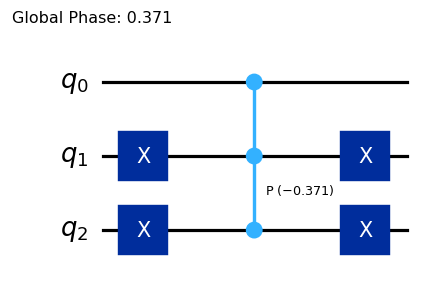

Local wires q0,q1,q2 correspond to external variables: [10, 6, 8]


In [6]:
# Check the direct SAT phaser against every assignment, including global phase.
probe_gamma = 0.371
probe = QuantumCircuit(N)
probe.h(range(N))
probe.compose(phaser_circuit(N,clauses,probe_gamma),inplace=True)
actual_phase_state = Statevector.from_instruction(probe).data
expected_phase_state = np.exp(-1j*probe_gamma*cost_diagonal)/np.sqrt(1<<N)
phaser_error = float(np.max(np.abs(actual_phase_state-expected_phase_state)))
assert np.allclose(actual_phase_state,expected_phase_state,atol=1e-10)
assert N==10 and M==8 and int(good.sum())==408
print(f'PASS: direct SAT phaser matches paper Eq. (4) on all {1<<N} assignments; max error={phaser_error:.3g}.')
print(f'Direct QAOA register: {N} data qubits; no product-replacement variables.')

# A uniform superposition has nonzero amplitude on every data assignment, so
# this checks every diagonal oracle phase and clean work flags in one evolution.
oracle_probe = QuantumCircuit(N+M)
oracle_probe.h(range(N))
oracle_probe.compose(sat_oracle_with_flags(N,clauses),inplace=True)
oracle_state = Statevector.from_instruction(oracle_probe).data
oracle_expected = np.zeros(1<<(N+M),dtype=complex)
oracle_expected[:1<<N] = np.where(good,-1,1)/np.sqrt(1<<N)
oracle_error = float(np.max(np.abs(oracle_state-oracle_expected)))
assert np.allclose(oracle_state,oracle_expected,atol=1e-9)
print(f'PASS: native SAT oracle phases on all {1<<N} assignments; all {M} flags return to zero; max error={oracle_error:.3g}.')
write_csv('direct_sat_verification.csv',[
    {'check':'phaser_paper_eq4','assignments':1<<N,'data_qubits':N,'work_flags':0,'max_abs_error':phaser_error,'passed':True},
    {'check':'native_SAT_oracle_clean_flags','assignments':1<<N,'data_qubits':N,'work_flags':M,'max_abs_error':oracle_error,'passed':True}])

first_clause=clauses[0]
local_clause=[[(i,sign) for i,(_,sign) in enumerate(first_clause)]]
save_figure(phaser_circuit(3,local_clause,probe_gamma).draw('mpl',fold=-1),'01_direct_SAT_clause_phaser')
print('Local wires q0,q1,q2 correspond to external variables:',[i+1 for i,_ in first_clause])


### 3.1 把全局相位画在电路上

上一张图左上角的 **Global Phase: 0.371** 就是全局相位。代码中施加它的语句是：

```python
qc.global_phase += float(gamma) * len(clauses)
```

Qiskit 将它记录在整条电路上，默认不画在线上。为了汇报时能看见，下方把同一个操作画成跨越所有量子线的 **$e^{i\phi}I$ 方块**。$I$ 表示所有位的取值都不变，只让整个状态乘 $e^{i\phi}$。

这个方块内部只有 `global_phase`，没有隐藏的 X、控制门或额外量子位；它是对同一个酉算符的画图表示，不表示需要额外的硬件门或独立训练参数。单独的全局相位不改变测量概率，不能用某一根线上的普通 $P(\phi)$ 门代替。

先用同一条 3 位子句举例：`X → 受控 P(-0.371) → X` 后面，显式接上 $e^{+i0.371}I$。下面比较完整复振幅，确认两种画法相同。

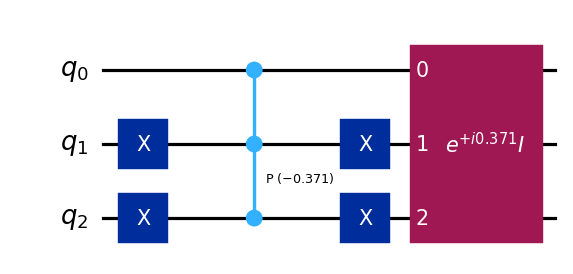

PASS: native and explicit global phase agree, max error=1.76e-16


In [7]:
first_clause_circuit = phaser_circuit(3, local_clause, probe_gamma)

def expose_global_phase(circuit, label):
    """把电路顶部的全局相位，等价地显示成跨越全部量子线的方块。"""
    visible = circuit.copy()
    angle = float(visible.global_phase)
    visible.global_phase = 0  # 移到下面的方块中，避免重复乘一次相位。

    phase_identity = QuantumCircuit(visible.num_qubits, name='global_phase')
    phase_identity.global_phase = angle  # 这个方块的全部作用：e^(i*angle) I。
    visible.append(phase_identity.to_gate(label=label), visible.qubits)
    return visible

explicit_clause = expose_global_phase(
    first_clause_circuit, rf'$e^{{+i{probe_gamma:.3f}}} I$')
fig = explicit_clause.draw('mpl', fold=-1)
fig.savefig(FIGURES/'01b_explicit_clause_global_phase.svg', bbox_inches='tight')
save_figure(fig, '01b_explicit_clause_global_phase')

toy_native = QuantumCircuit(3); toy_native.h(range(3))
toy_explicit = toy_native.copy()
toy_native.compose(first_clause_circuit, inplace=True)
toy_explicit.compose(explicit_clause, inplace=True)
clause_view_error = float(np.max(np.abs(
    Statevector.from_instruction(toy_native).data
    - Statevector.from_instruction(toy_explicit).data)))
assert clause_view_error < 1e-10
print(f'PASS: native and explicit global phase agree, max error={clause_view_error:.3g}')

## 4. 按论文记号构建 QAOA，并做本地参数优化

论文式 (2)–(3) 给出

$$|\mathrm{QAOA}\rangle=U_{\mathrm{QAOA}}|+\rangle^{\otimes n},\qquad
U_{\mathrm{QAOA}}=\prod_{\ell=1}^{p}e^{-i\beta_\ell H_M}e^{-i\gamma_\ell H_C}.$$

沿用论文 $H_M=\tfrac12\sum_iX_i$，每层先作用相位器，再在每根数据线上施加 $R_x(\beta_\ell)$。

本地训练直接最小化论文成本的期望值：

$$\langle H_C\rangle=-\sum_xP(x)\sum_{j=1}^{m}C_j(x).$$


**本地选择，非论文给定的训练流程：** L-BFGS-B、3 个初值、每个初值最多 100 次迭代，以及从较浅层结果继续训练。论文引用其 Ref. [1] 的已优化参数与随机 8-SAT 成功率规律，没有给出本 notebook 这套优化器配置。

每个 p 层电路有 2p 个角度。这里使用精确态矢量计算期望值，1000 shots 留到训练结束后的抽样统计。训练评分来自原始子句，满足解列表仅用于独立核验和成功率统计。


In [8]:
fits={}
warm=None
for p in P_VALUES:
    if warm is not None and p<len(warm['gammas']): warm=None
    fit=train_qaoa(N,cost_diagonal,good,p,TRAIN_SEED+p,restarts=RESTARTS,maxiter=MAXITER,warm=warm)
    fits[p]=fit; warm=fit
    print(f'p={p}: <H_C>={fit["expected_cost"]:.6f}, <#UNSAT>={fit["expected_cost"]+M:.6f}, '
          f'P(SAT)={fit["success"]:.6f}, pretrain={fit["train_time_s"]:.4f}s, evals={fit["nfev"]}')
fit=fits[P_SELECTED]
gammas,betas=fit['gammas'],fit['betas']
# Warm start for p=2 depends on p=1, so include both actual training costs.
PRETRAIN_S=sum(fits[p]['train_time_s'] for p in P_VALUES if p<=P_SELECTED)
qaoa_qc=qaoa_circuit(N,clauses,gammas,betas)
psi=Statevector.from_instruction(qaoa_qc).data
assert np.allclose(psi,fit['state'],atol=1e-10)
assert np.isclose(np.abs(psi)**2 @ cost_diagonal,fit['expected_cost'],atol=1e-10)
P0=float(np.abs(psi[good])@np.abs(psi[good]))
param_rows=[]
for p,result in fits.items():
    for layer,(gamma,beta) in enumerate(zip(result['gammas'],result['betas']),1):
        param_rows.append({'p':p,'layer':layer,'gamma_rad':float(gamma),'beta_rad':float(beta),
                           'expected_cost':result['expected_cost'],
                           'expected_unsat':result['expected_cost']+M,'P_sat_exact':result['success']})
show_table(param_rows); write_csv('trained_parameters.csv',param_rows)
write_csv('training_runs.csv',[{'p':p,'objective':'paper_v1_Eq4_H_C',
    'expected_cost':r['expected_cost'],'expected_unsat':r['expected_cost']+M,
    'P_sat_exact':r['success'],'pretrain_s':r['train_time_s'],'evaluations':r['nfev']}
    for p,r in fits.items()])
write_csv('training_convergence.csv',[{'p':p,'evaluation':int(row[0]),
    'expected_cost':row[1],'expected_unsat':row[1]+M,'P_sat':row[2]}
    for p,result in fits.items() for row in result['history']])
print('Objective: minimize <H_C> from paper Eq. (4). #UNSAT is an explanatory diagnostic.')


p=1: <H_C>=-7.844557, <#UNSAT>=0.155443, P(SAT)=0.883289, pretrain=0.0264s, evals=168
p=2: <H_C>=-7.946090, <#UNSAT>=0.053910, P(SAT)=0.955870, pretrain=0.0509s, evals=248


p=3: <H_C>=-7.979531, <#UNSAT>=0.020469, P(SAT)=0.985406, pretrain=0.1544s, evals=521

p,layer,gamma_rad,beta_rad,expected_cost,expected_unsat,P_sat_exact
1,1,-0.8782242285276348,0.7749366821874749,-7.844556783700592,0.15544321629940772,0.8832892148743774
2,1,0.7704655439658488,-0.5471347241154833,-7.946089711033137,0.05391028896686301,0.9558699561672667
2,2,-2.0300788010017228,0.33099127050764693,-7.946089711033137,0.05391028896686301,0.9558699561672667
3,1,0.41877652510798524,-3.381515783851649,-7.979530848313244,0.020469151686755893,0.9854063425315338
3,2,-6.790429046336439,2.117731909489515,-7.979530848313244,0.020469151686755893,0.9854063425315338
3,3,-5.175913546506189,-0.7573940983759978,-7.979530848313244,0.020469151686755893,0.9854063425315338


Objective: minimize <H_C> from paper Eq. (4). #UNSAT is an explanatory diagnostic.


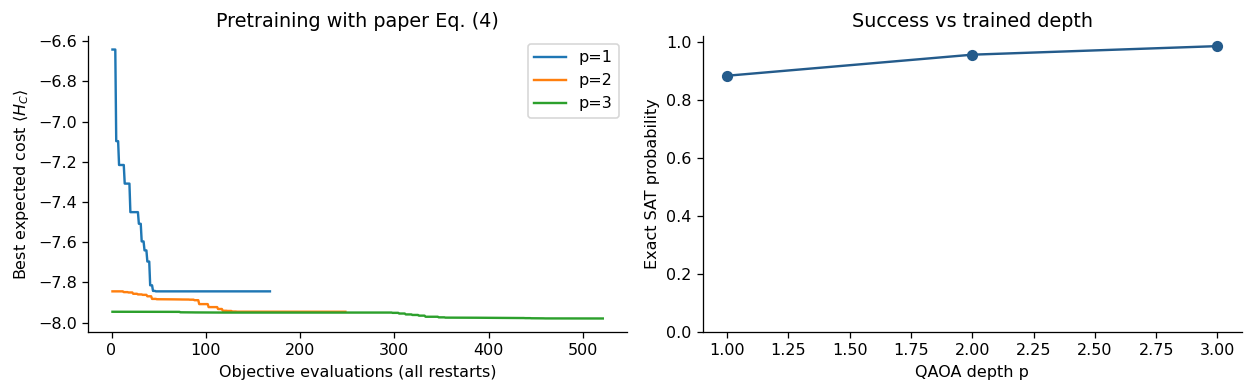

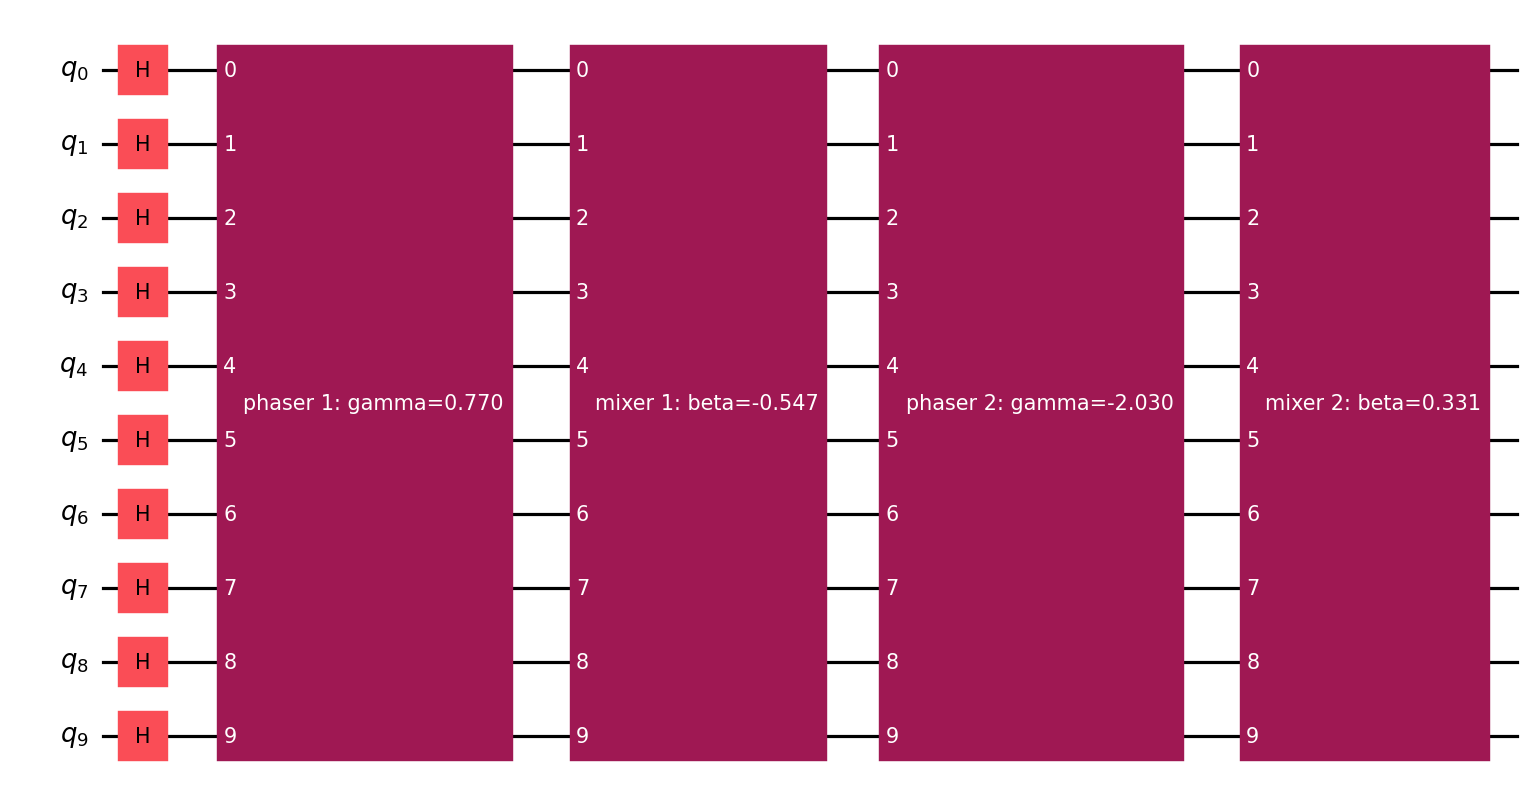

In [9]:
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
for p,result in fits.items():
    history=result['history']; best=np.minimum.accumulate(history[:,1])
    axes[0].plot(history[:,0],best,label=f'p={p}')
axes[0].set(xlabel='Objective evaluations (all restarts)',ylabel=r'Best expected cost $\langle H_C\rangle$',title='Pretraining with paper Eq. (4)')
axes[0].legend()
axes[1].plot(P_VALUES,[fits[p]['success'] for p in P_VALUES],'o-',color=COLORS['QAOA'])
axes[1].set(xlabel='QAOA depth p',ylabel='Exact SAT probability',ylim=(0,1.02),title='Success vs trained depth')
fig.tight_layout(); save_figure(fig,'02_pretraining_and_depth')
save_figure(qaoa_circuit(N,clauses,gammas,betas,boxed=True).draw('mpl',fold=-1),'03_main_QAOA_circuit')

### 展开大方框：QAOA 的实际门电路

上面的概览图使用 `boxed=True`，把子电路包成方框。实际代码在 `boxed=False` 时会直接组合内部的门。
下面使用本次训练的同一组角度，画出两层 QAOA、第一层 phaser 和第一层 mixer。

- 第一层相位器使用下表本次训练得到的 $\gamma_1$；失败图样上的相位门角度为 $-\gamma_1$。
- 第一层 mixer 在每根数据线上施加 $R_x(\beta_1)$，$\beta_1$ 同样取自本次参数表。
- 图中的 `L1/L2` 是层号，`color 1…4` 是分色批次；同色子句使用同一个 gamma。
- 为了显示边界添加的 barrier 仅辅助阅读，不改变酉变换；它们不是新增的物理操作。
- 多控相位门仍是逻辑门。更底层的单、双比特门版本另存为 PDF/SVG 和文本，避免将长电路挤成大方框。

`q0…q9` 对应外部 CNF 的 `x1…x10`。多控相位门的连线和蓝点表示控制条件，不是测量结果。


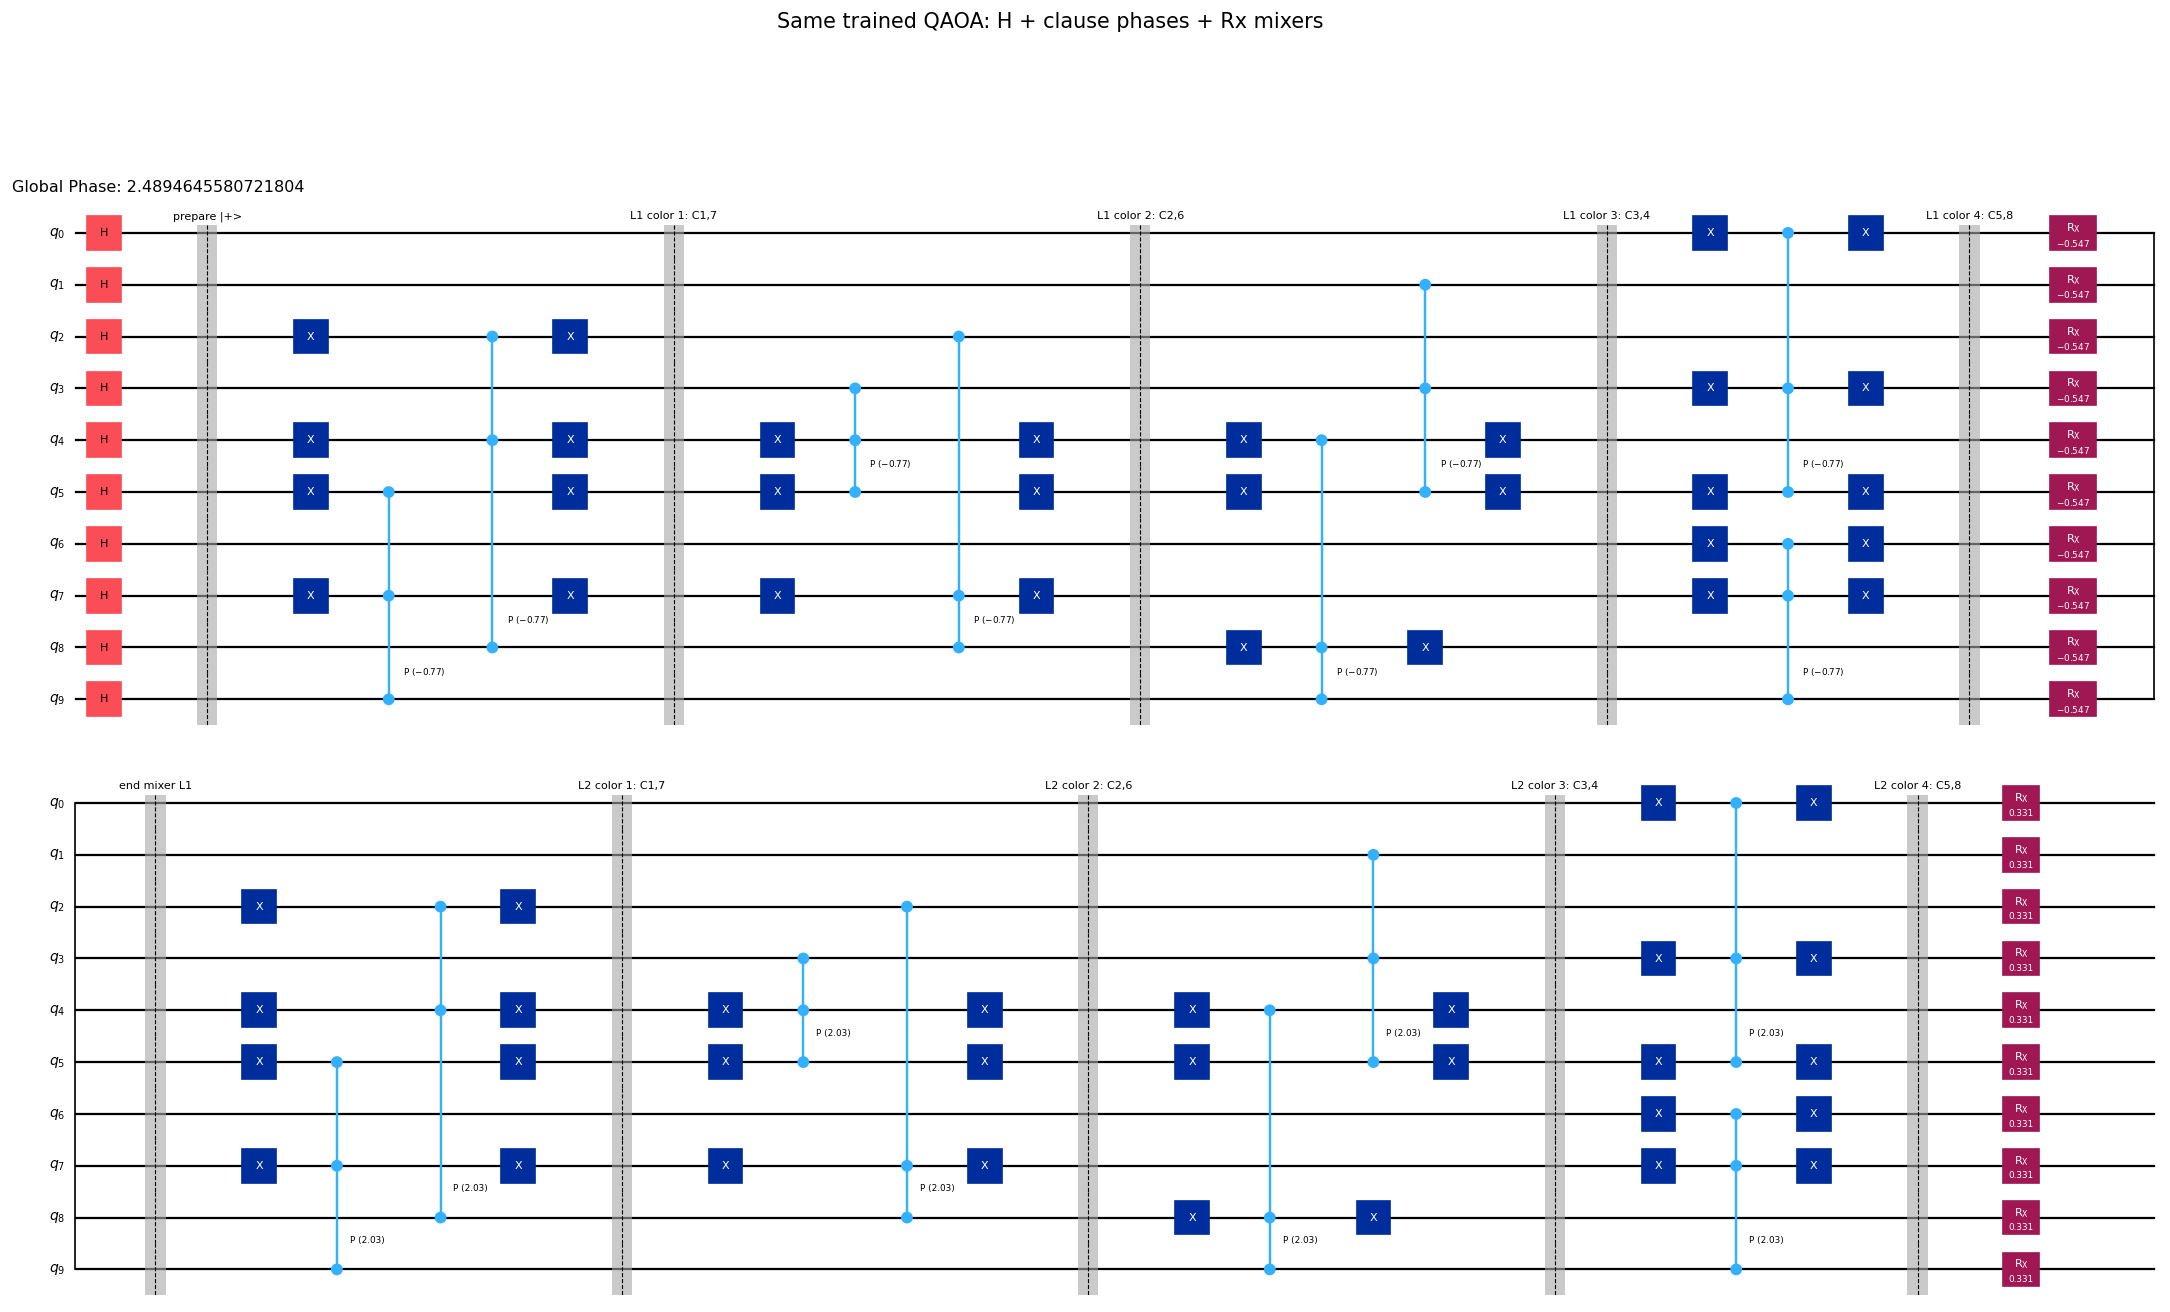

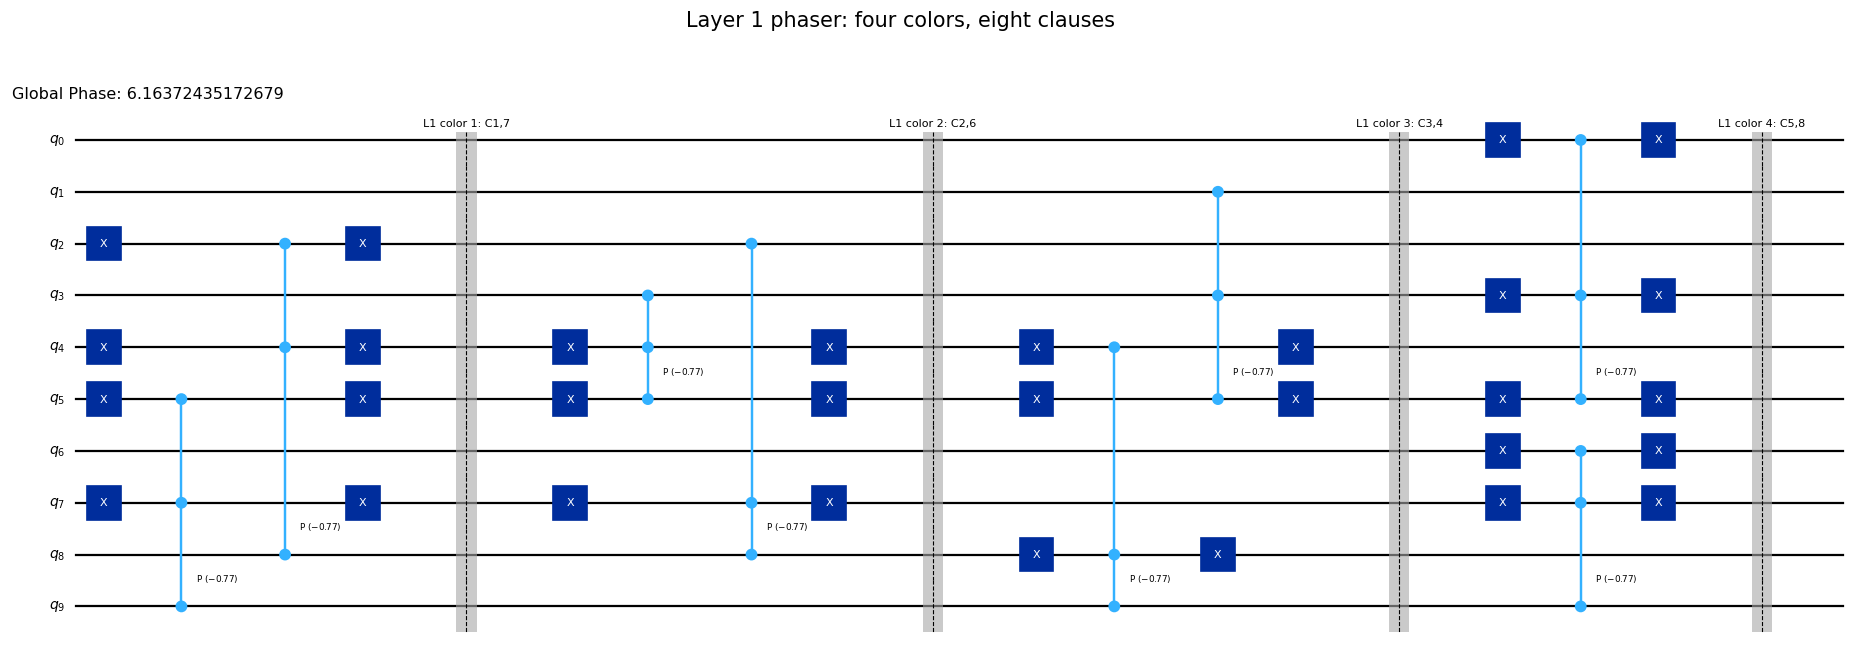

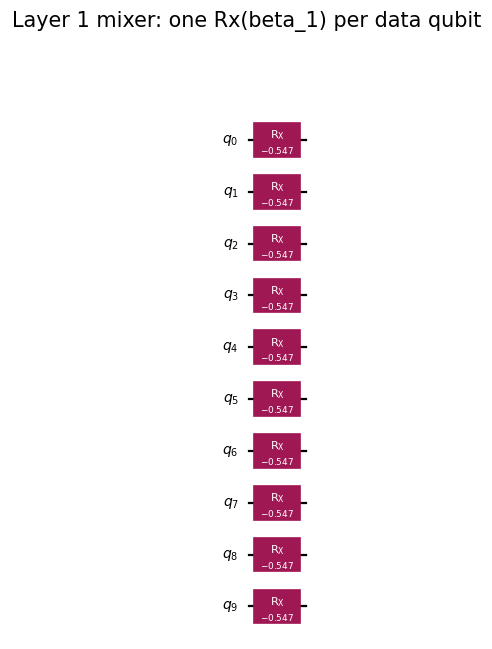

PASS: expanded and elementary QAOA views match the original trained circuit.
QAOA logical gates: {'x': 60, 'rx': 20, 'mcphase': 16, 'h': 10}
QAOA elementary gates: {'rz': 112, 'cx': 96, 'x': 60, 'rx': 20, 'h': 10}


[完整基础门 QAOA PDF](../results/figures/03e_QAOA_elementary_gates.pdf) · [可缩放 SVG](../results/figures/03e_QAOA_elementary_gates.svg) · [逐门文本](../results/figures/03e_QAOA_elementary_gates.txt)

In [10]:
# These are additional views of the SAME trained circuit, not a new fit.
def export_circuit_view(circuit, name, title, fold=36, show=True, png=True):
    figure=circuit.draw('mpl',fold=fold,scale=0.7,style={'fontsize':10,'subfontsize':8})
    figure.suptitle(title,fontsize=13,y=1.005)
    for extension in ('pdf','svg'):
        figure.savefig(FIGURES/f'{name}.{extension}',bbox_inches='tight')
    if png:figure.savefig(FIGURES/f'{name}.png',dpi=150,bbox_inches='tight')
    (FIGURES/f'{name}.txt').write_text(str(circuit.draw('text',fold=120)),encoding='utf-8')
    if show:display(figure)
    plt.close(figure)

def readable_phaser(n, clauses, gamma, layer):
    view=QuantumCircuit(n,name=f'phaser L{layer}')
    for color,batch in enumerate(greedy_clause_colors(clauses),1):
        view.compose(phaser_circuit(n,[clauses[j] for j in batch],gamma),inplace=True)
        labels=','.join(str(j+1) for j in batch)
        view.barrier(label=f'L{layer} color {color}: C{labels}')
    return view

qaoa_gate_view=QuantumCircuit(N,name='expanded A')
qaoa_gate_view.h(range(N))
qaoa_gate_view.barrier(label='prepare |+>')
for layer,(gamma,beta) in enumerate(zip(gammas,betas),1):
    qaoa_gate_view.compose(readable_phaser(N,clauses,gamma,layer),inplace=True)
    qaoa_gate_view.compose(mixer_circuit(N,beta),inplace=True)
    if layer<len(gammas):qaoa_gate_view.barrier(label=f'end mixer L{layer}')
qaoa_reference=Statevector.from_instruction(qaoa_circuit(N,clauses,gammas,betas))
assert np.allclose(Statevector.from_instruction(qaoa_gate_view).data,qaoa_reference.data,atol=1e-10)
export_circuit_view(qaoa_gate_view,'03b_main_QAOA_expanded','Same trained QAOA: H + clause phases + Rx mixers',fold=40)
export_circuit_view(readable_phaser(N,clauses,gammas[0],1),'03c_first_phaser_expanded','Layer 1 phaser: four colors, eight clauses',fold=38)
export_circuit_view(mixer_circuit(N,betas[0]),'03d_first_mixer_expanded','Layer 1 mixer: one Rx(beta_1) per data qubit',fold=-1)

# A specified abstract basis, without a device topology or hardware calibration.
elementary_basis=['x','h','rx','rz','cx']
qaoa_elementary=transpile(qaoa_circuit(N,clauses,gammas,betas),basis_gates=elementary_basis,optimization_level=0,qubits_initially_zero=False)
assert Statevector.from_instruction(qaoa_elementary).equiv(qaoa_reference)
export_circuit_view(qaoa_elementary,'03e_QAOA_elementary_gates','QAOA decomposed into x/h/rx/rz/cx',fold=55,show=False,png=False)
print('PASS: expanded and elementary QAOA views match the original trained circuit.')
print('QAOA logical gates:',dict(qaoa_circuit(N,clauses,gammas,betas).count_ops()))
print('QAOA elementary gates:',dict(qaoa_elementary.count_ops()))
display(Markdown('[完整基础门 QAOA PDF](../results/figures/03e_QAOA_elementary_gates.pdf) · [可缩放 SVG](../results/figures/03e_QAOA_elementary_gates.svg) · [逐门文本](../results/figures/03e_QAOA_elementary_gates.txt)'))


### 4.1 训练好的完整 QAOA 电路：展开具体门和全局相位

这张图使用刚才训练得到的 **p=2** 角度，包含全部 10 根数据线、全部 8 条子句的两轮操作。`q0` 对应 $x_1$，`q9` 对应 $x_{10}$。与前面 3 线局部示例的重新编号不同。

从左到右读：

1. **H：** 每根线施加 H，制备均匀叠加态。
2. **第 1 层相位器：** 对全部 8 条子句执行 X、受控 $P(-\gamma_1)$、X；随后跨全部线的 $e^{i8\gamma_1}I$ 方块补上这一层的全局相位。
3. **第 1 层混合器：** 每根线施加 $R_x(\beta_1)$。
4. **第 2 层：** 同样执行 8 条子句、$e^{i8\gamma_2}I$，然后每根线施加 $R_x(\beta_2)$。

图中只把全局相位画成跨线方块，所有子句和混合操作均已展开。竖向虚线帮助区分阶段，没有物理操作；若图折成多行，从一组量子线的右端接到下一组的左端。此处展示测量前的制备电路，后面的 1000 次抽样就是读取它的输出。

两层累计全局相位为 $\Phi=8(\gamma_1+\gamma_2)$，与 Qiskit 顶部显示值允许相差 $2\pi$ 的整数倍。下方同时检查显式画法与训练时的标准电路复振幅相同，避免漏加或重复加全局相位。

layer,gamma_rad,global_phase_rad = m*gamma
1,0.7704655439658488,6.16372435172679
2,-2.0300788010017228,-16.240630408013782


Total phase: -10.076906 rad; modulo 2*pi: 2.489465 rad
Standard circuit Global Phase: 2.489465 rad
PASS: displayed circuit = trained circuit, max amplitude error=1.14e-16


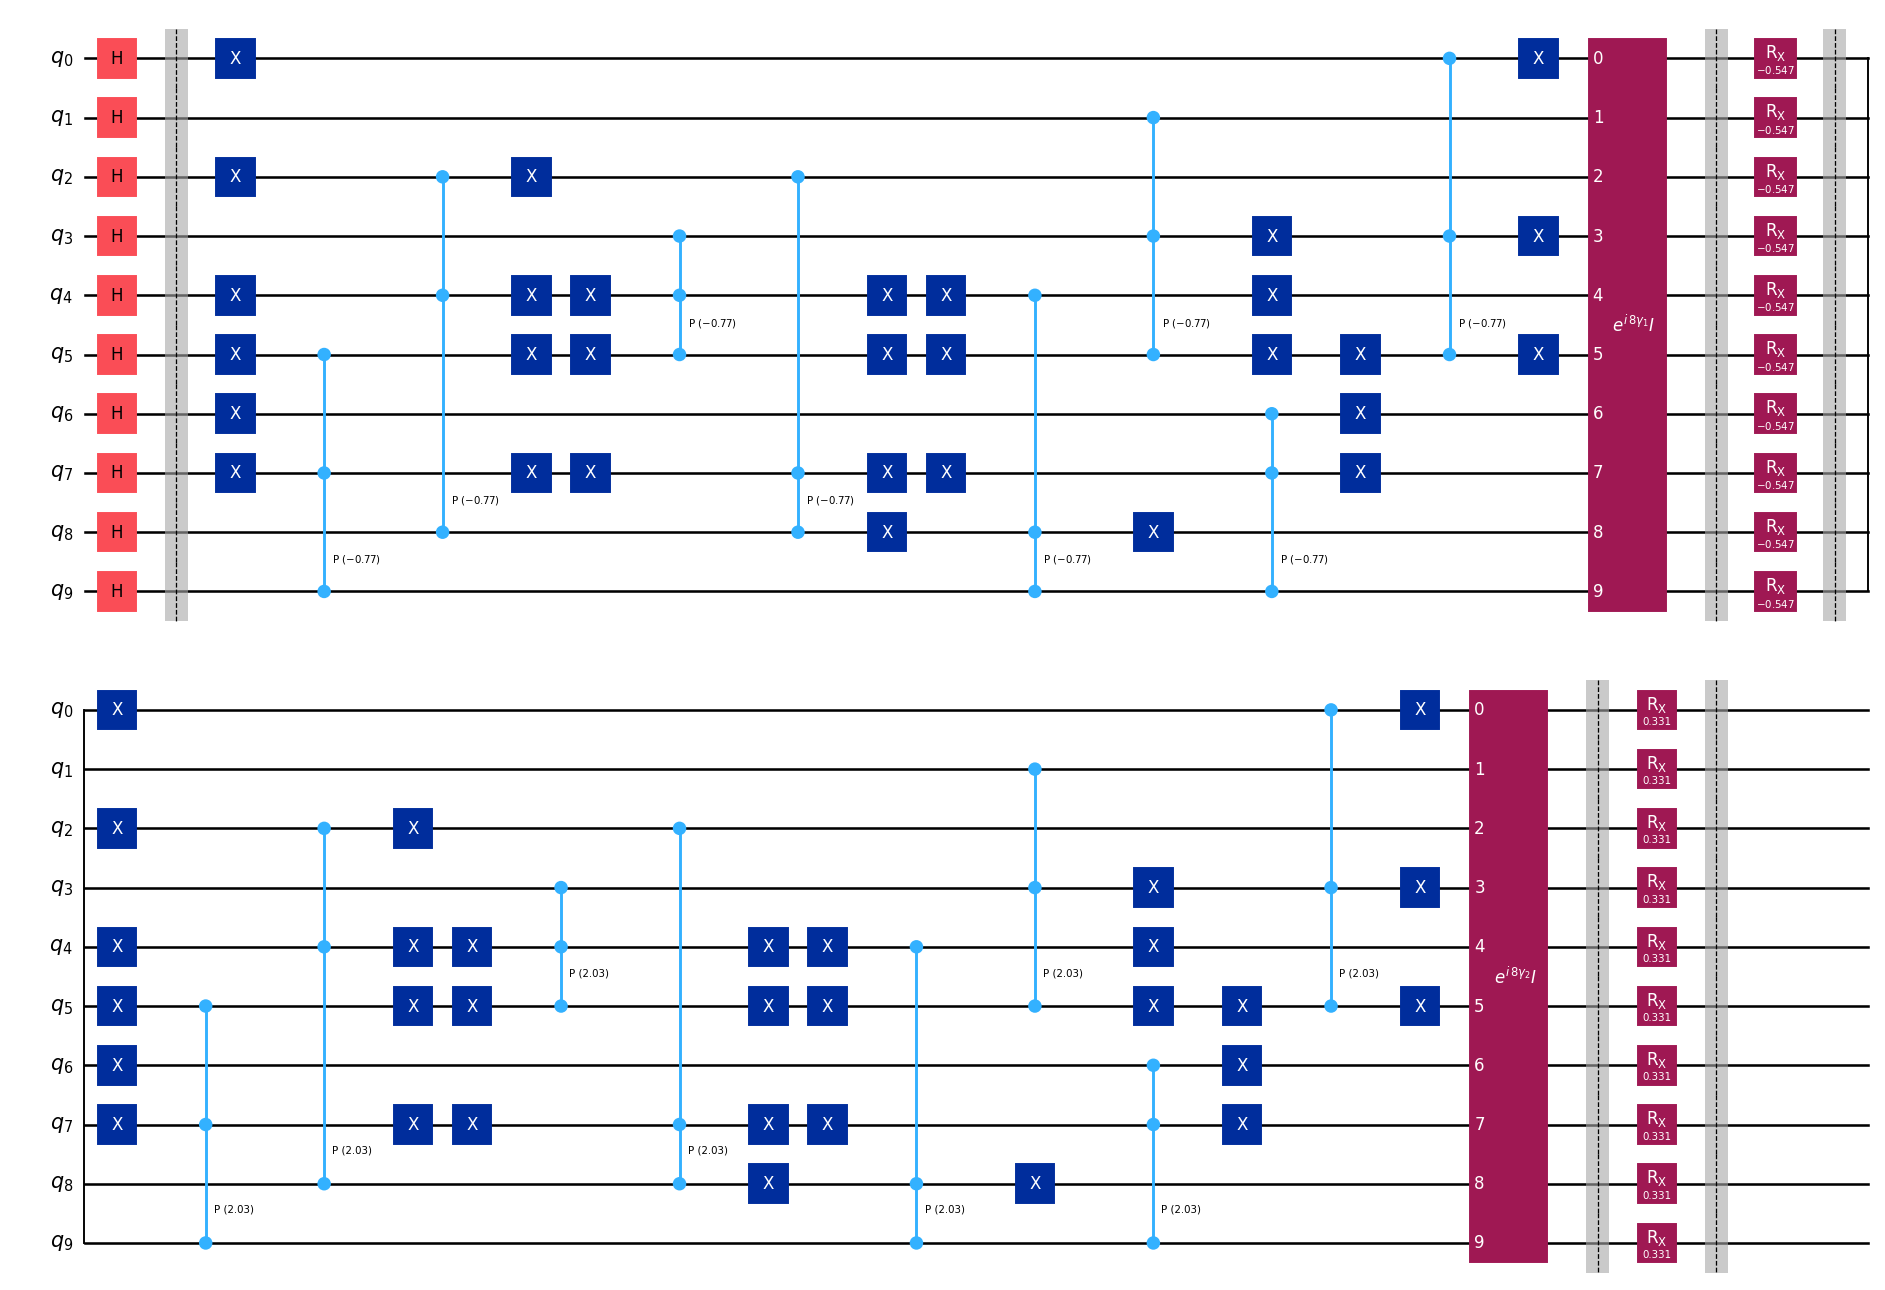

H -> all clauses (gamma_1) -> global phase -> Rx(beta_1) -> all clauses (gamma_2) -> global phase -> Rx(beta_2)


In [11]:
# 完整电路逐层搭建；对子句使用原来的 phaser_circuit，并展开其具体门。
qaoa_visible = QuantumCircuit(N, name='Complete QAOA')
qaoa_visible.h(range(N))
qaoa_visible.barrier()
phase_rows = []
for layer, (gamma, beta) in enumerate(zip(gammas, betas), start=1):
    phaser = phaser_circuit(N, clauses, gamma)
    phase_label = rf'$e^{{i\,{M}\gamma_{{{layer}}}}} I$'
    qaoa_visible.compose(expose_global_phase(phaser, phase_label), inplace=True)
    qaoa_visible.barrier()
    qaoa_visible.compose(mixer_circuit(N, beta), inplace=True)
    qaoa_visible.barrier()
    phase_rows.append({'layer':layer, 'gamma_rad':float(gamma),
                       'global_phase_rad = m*gamma':float(M*gamma)})

visible_state = Statevector.from_instruction(qaoa_visible).data
circuit_view_error = float(np.max(np.abs(visible_state-psi)))
assert circuit_view_error < 1e-10  # 比较复振幅，不忽略全局相位。
assert qaoa_visible.count_ops().get('global_phase', 0) == P_SELECTED
show_table(phase_rows)
raw_global_phase = float(M*np.sum(gammas))
print(f'Total phase: {raw_global_phase:.6f} rad; modulo 2*pi: '
      f'{raw_global_phase % (2*np.pi):.6f} rad')
print(f'Standard circuit Global Phase: {float(qaoa_qc.global_phase):.6f} rad')
print(f'PASS: displayed circuit = trained circuit, max amplitude error={circuit_view_error:.3g}')

fig = qaoa_visible.draw('mpl', fold=30, scale=0.8)
fig.savefig(FIGURES/'03f_QAOA_explicit_global_phase.png', dpi=170, bbox_inches='tight')
fig.savefig(FIGURES/'03f_QAOA_explicit_global_phase.svg', bbox_inches='tight')
fig.savefig(FIGURES/'03f_QAOA_explicit_global_phase.pdf', bbox_inches='tight')
display(fig); plt.close(fig)
print('H -> all clauses (gamma_1) -> global phase -> Rx(beta_1) -> '
      'all clauses (gamma_2) -> global phase -> Rx(beta_2)')

write_csv('circuit_display_verification.csv', [
    {'check':'clause_explicit_global_phase', 'qubits':3,
     'max_abs_error':clause_view_error, 'passed':clause_view_error < 1e-10},
    {'check':'complete_QAOA_explicit_global_phase', 'qubits':N,
     'max_abs_error':circuit_view_error, 'passed':circuit_view_error < 1e-10}])

## 5. 固定 R 的 QAOA+AA：准确公式与论文近似

先准备 $|\psi\rangle=A|0^n\rangle$，其中 $A=U_{\rm QAOA}H^{\otimes n}$。
随后每轮由右向左作用

$$G=A O_0 A^\dagger O_C,\qquad O_0=I-2|0^n\rangle\langle0^n|,\quad O_C=I-2\Pi_{\rm SAT}.$$

相对 Brassard et al. Eq. (1) 的 $-A S_0A^{-1}S_\chi$ 只差每轮整体负号，不影响概率。
论文 Eq. (6) 如果将 $U_{\rm QAOA}$ 仅解释为 Eq. (3) 的层乘积，就须补入 H 的基变换；本实现使用完整 A，避免把关于 $|0\rangle$ 与关于 $|+\rangle$ 的反射混淆。
O₀ 内最后一根线上的 H-MCX-H 仅将受控 X 变成受控 Z。

令 $P_0=\langle\psi|\Pi_{\rm SAT}|\psi\rangle$，$\theta=\arcsin\sqrt{P_0}$。由 Brassard et al. Eqs. (5),(8)：

$$P_R=\sin^2[(2R+1)\theta].$$

论文正文使用近似 $R\simeq\pi/(4\sqrt{P_0})$。这里同时报告其**向下取整**与第一峰附近
$\pi/(4\theta)-1/2$ 的两侧整数，并保留 $R=0$ 候选；固定实验选第一峰最佳整数。
这是**知道精确 P 的教学模式**，不能假装真实运行时免费知道 P。
若训练已让 P 很大，最优 R 可以为 0；强行多放大一轮会越过峰值。

主数值模拟的 $O_C$ 用精确对角门，避免保留始终归零的辅助寄存器。
下一张图给出实际可逆子句计算版本：8 个 flags，计算 OR → flags 的 AND 做相位翻转 → 反计算。
门时间模型计入这个可逆实现，而非把对角表查询当成免费门。

P0= 0.9558699561672634 theta= 1.3591482145190943
Paper pi/(4 sqrt(P0))= 0.8033235070551978 ; floor= 0
Chosen first-peak integer R= 0
QAOA P=0.955870; QAOA+AA (R=0) P=0.955870
This sparse CNF already has high trained success: AA is not needed at the first peak.


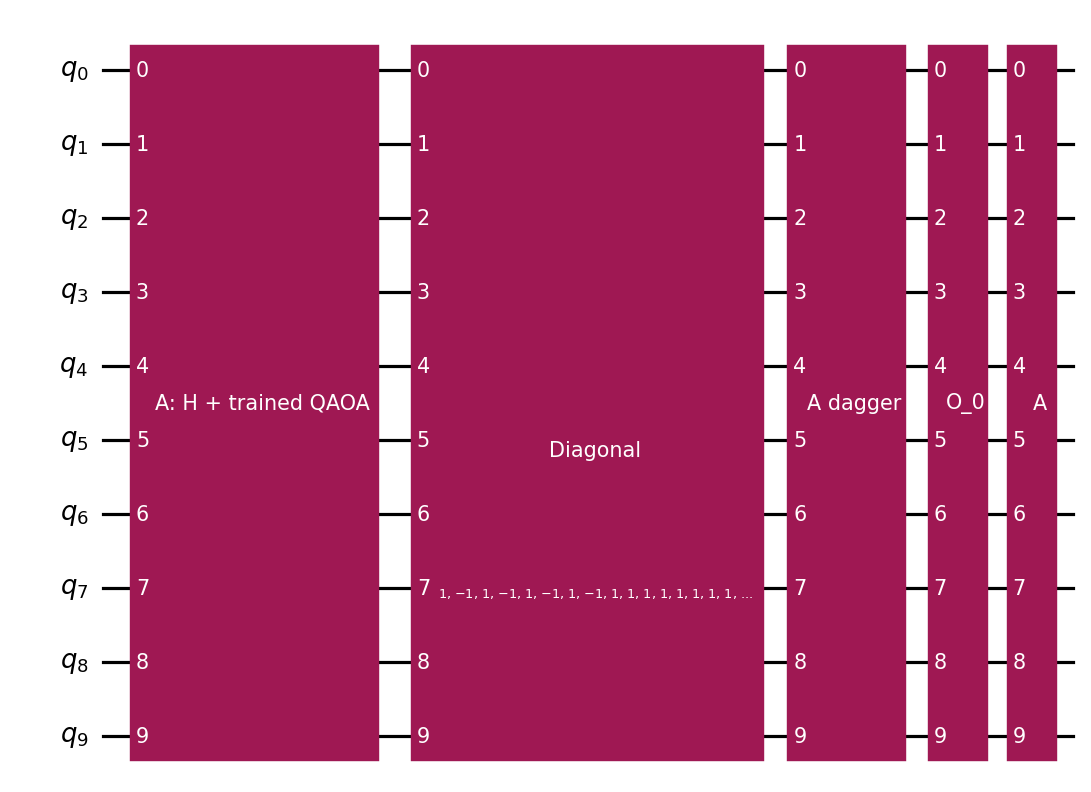

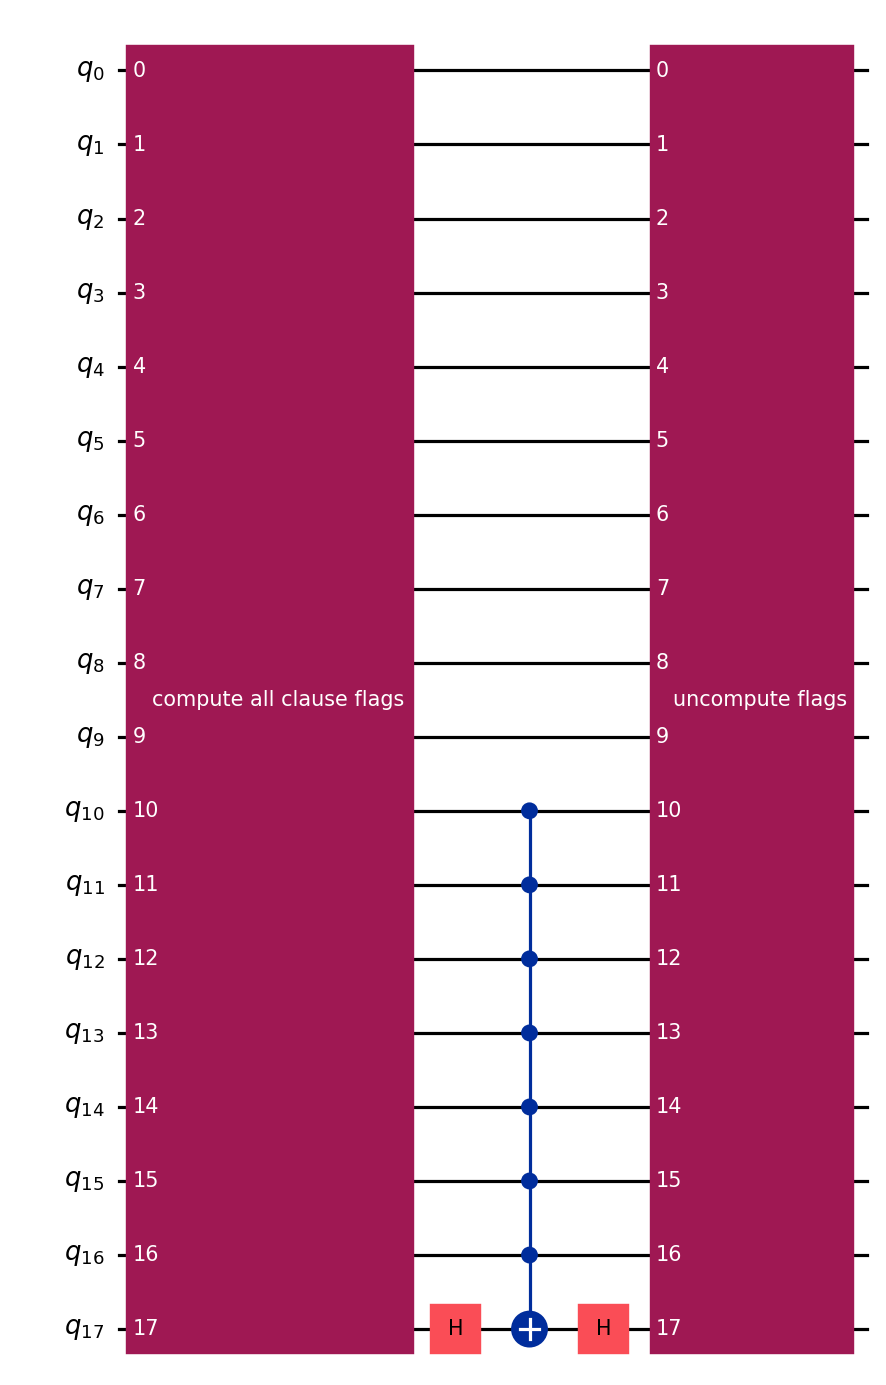

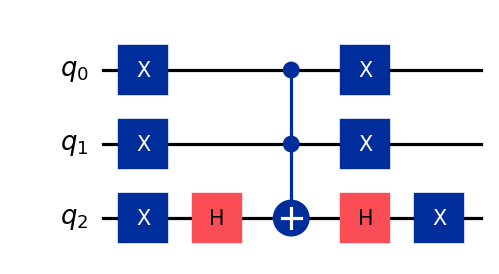

The main 10-variable native SAT oracle was verified on all 1024 assignments in section 3.


In [12]:
round_choices=choose_rounds(P0)
R_FIXED=round_choices['best_first_peak']
print('P0=',P0,'theta=',np.arcsin(np.sqrt(P0)))
print('Paper pi/(4 sqrt(P0))=',round_choices['paper_continuous'], '; floor=',round_choices['paper_floor'])
print('Chosen first-peak integer R=',R_FIXED)
aa_qc=aa_circuit(N,clauses,gammas,betas,good,R_FIXED)
psi_aa=Statevector.from_instruction(aa_qc).data
assert Statevector(psi_aa).equiv(Statevector(amplify(psi,good,R_FIXED)))
P_AA=float(np.abs(psi_aa[good])@np.abs(psi_aa[good]))
assert np.isclose(P_AA,aa_probability(P0,R_FIXED),atol=1e-10)
print(f'QAOA P={P0:.6f}; QAOA+AA (R={R_FIXED}) P={P_AA:.6f}')
if R_FIXED==0: print('This sparse CNF already has high trained success: AA is not needed at the first peak.')
# Always draw a one-iterate illustration so the AA blocks remain inspectable.
save_figure(aa_circuit(N,clauses,gammas,betas,good,1,boxed=True).draw('mpl',fold=-1),'04_one_AA_iteration_illustration')
save_figure(sat_oracle_with_flags(N,clauses,boxed=True).draw('mpl',fold=-1),'05_reversible_SAT_oracle')
save_figure(zero_oracle(3).draw('mpl',fold=-1),'06_zero_state_reflection')
print('The main 10-variable native SAT oracle was verified on all 1024 assignments in section 3.')


### 展开大方框：$O_C$ 内部怎样核验 SAT

下面给出**从原始 CNF 计算的可逆版本**，按“计算 flags → 对全满足翻相位 → 反计算”展开。
数据线 `x0…x9` 对应外部变量 `x1…x10`；工作线 `a0…a7` 分别记录 `C1…C8` 是否满足。
它与主数值模拟使用的对角相位 oracle 在工作位初始为零时等价。主图中对角门没有被当作真实硬件免费操作。

先看完整 18 根线，再看两个小模块：

1. **计算 C1 的 flag**：实际子句是 $\neg x_{10}\lor x_6\lor x_8$。四根局部线标为 `x10,x6,x8,a1`。初始 `a1=0`，操作后 `a1=C1(x)`。
2. **全部 flags 的 AND 相位**：8 根工作线全为 1 时，振幅乘以 -1；随后反计算恢复全部工作位。

受控 X 的图形是若干实心控制点连到一个带加号的目标；它只翻转目标位。H—多控 X—H 实现多控 Z。
逻辑 MCX 还可以继续分解；最后的小图展示同一个 C1 计算模块的单、双比特门版本。
独立模块分解使用 `qubits_initially_zero=False`，不假设数据输入是零态。等价性检查允许统一的全局相位差，仍严格检查相对相位及 flags 归零。


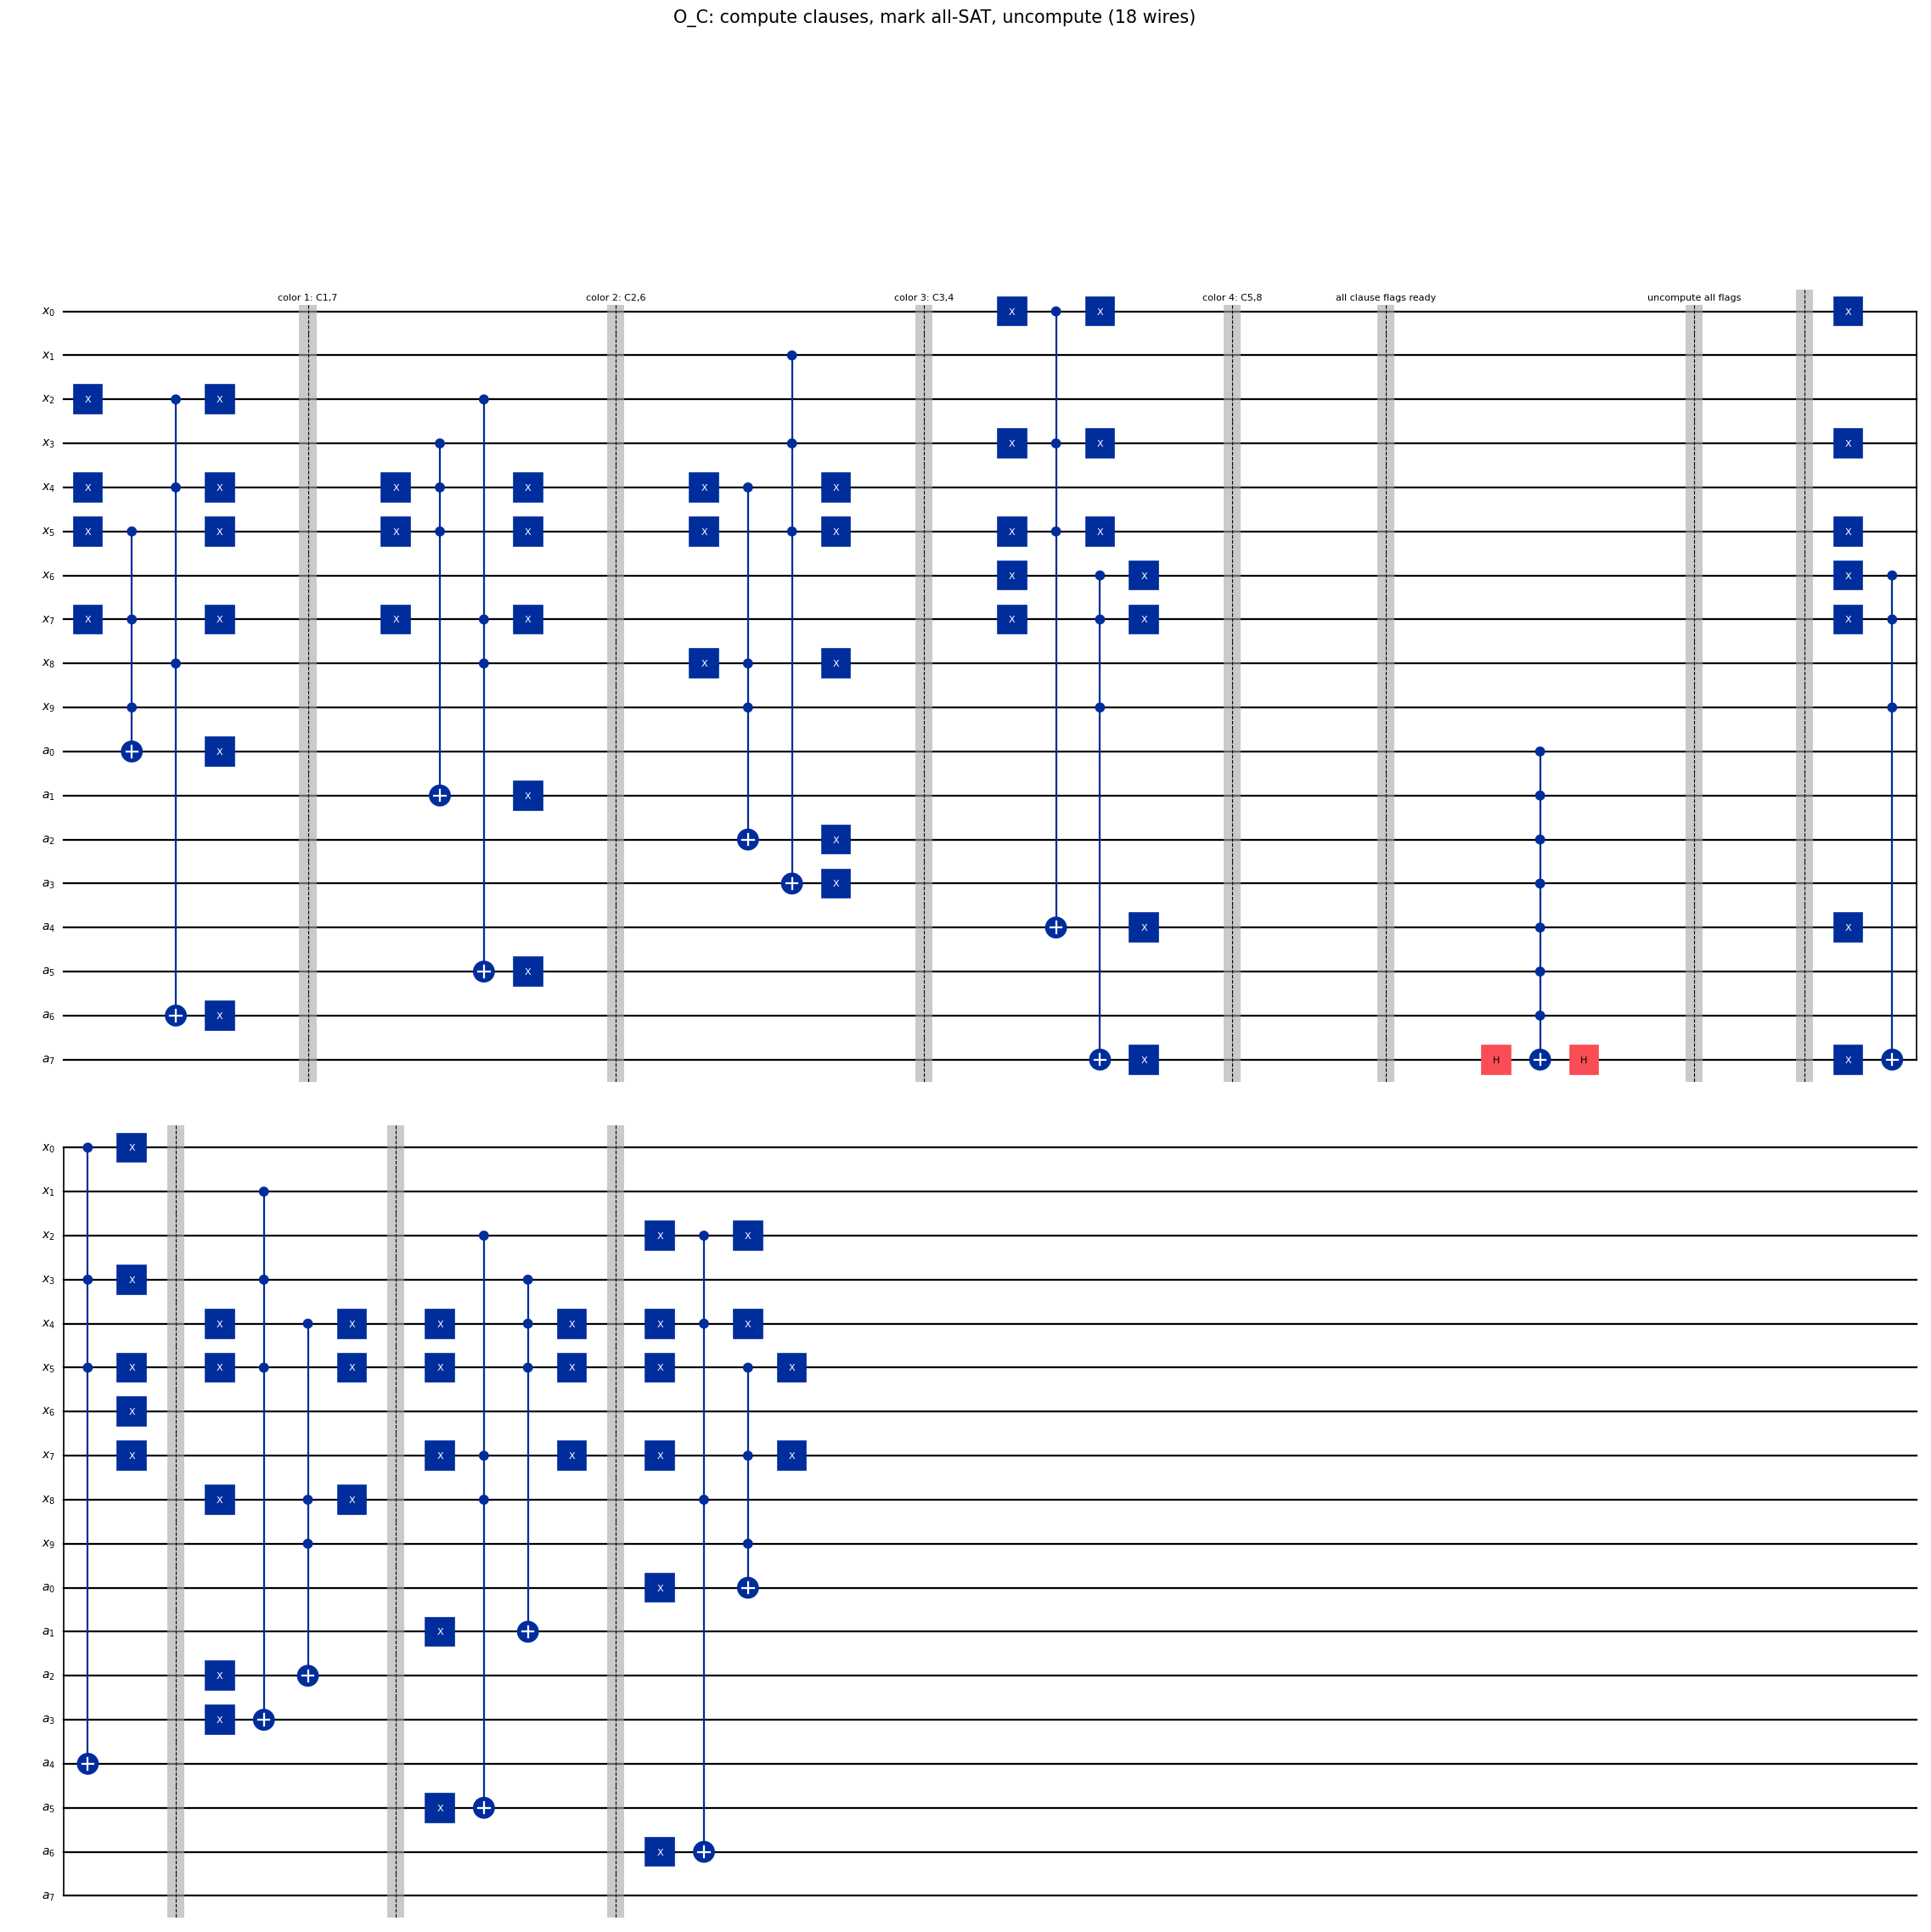

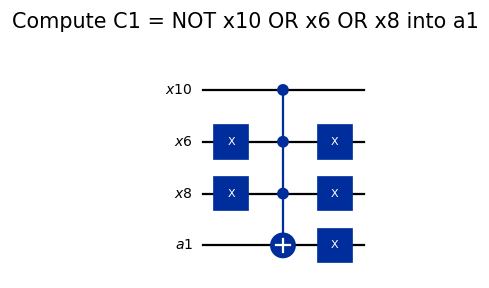

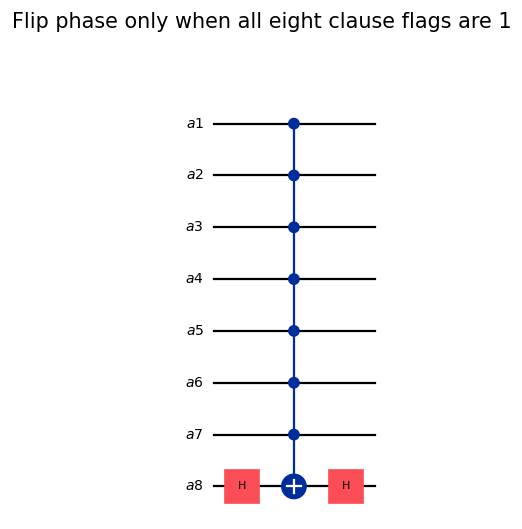

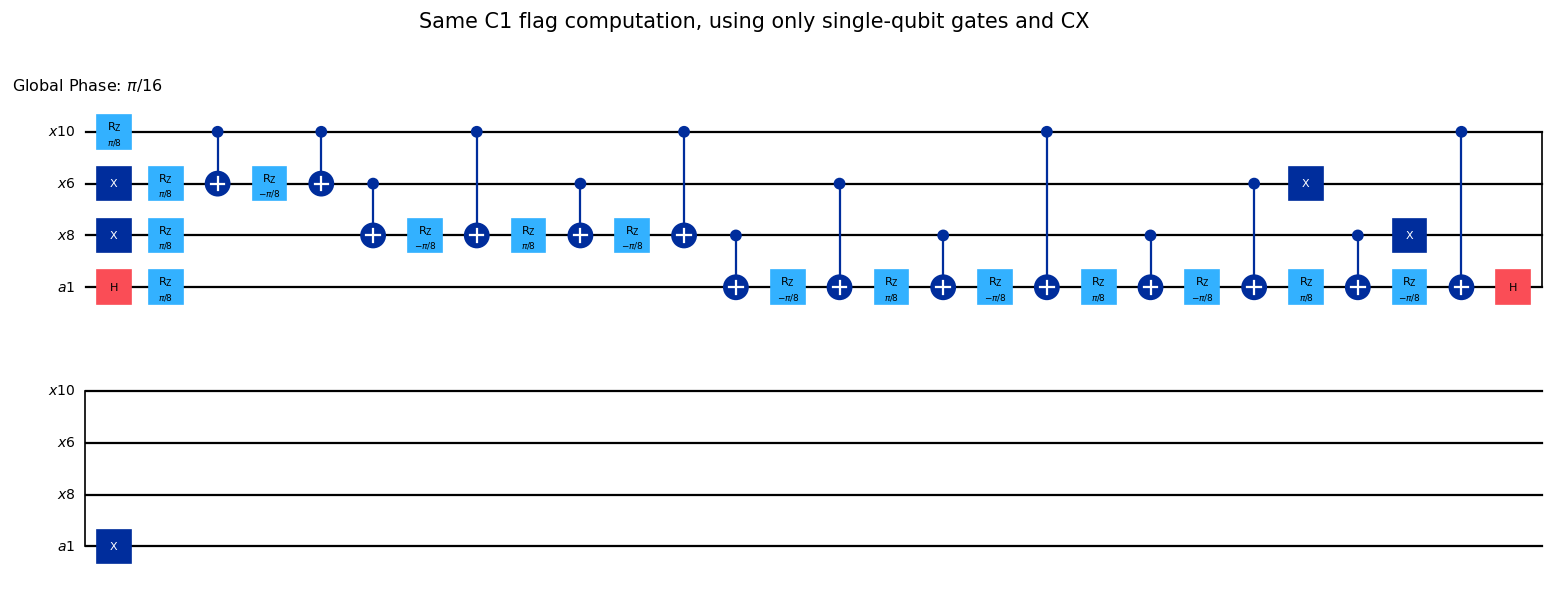

PASS: expanded O_C and its elementary decomposition preserve every SAT phase and clean flags.
O_C elementary gate counts: {'rz': 294, 'cx': 274, 'x': 76, 'h': 58}
Elementary O_C probe max amplitude error: 1.8771354712516973e-16


[完整基础门 O_C PDF](../results/figures/05f_SAT_oracle_elementary_gates.pdf) · [可缩放 SVG](../results/figures/05f_SAT_oracle_elementary_gates.svg) · [逐门文本](../results/figures/05f_SAT_oracle_elementary_gates.txt)

In [13]:
from qiskit import QuantumRegister
from qiskit.quantum_info import Operator

data_register=QuantumRegister(N,'x')
flag_register=QuantumRegister(M,'a')
compute_view=QuantumCircuit(data_register,flag_register,name='compute clauses')
for color,batch in enumerate(greedy_clause_colors(clauses),1):
    for j in batch:clause_or_xor(compute_view,clauses[j],N+j)
    compute_view.barrier(label=f'color {color}: C'+','.join(str(j+1) for j in batch))
oc_gate_view=QuantumCircuit(data_register,flag_register,name='expanded O_C')
oc_gate_view.compose(compute_view,inplace=True)
oc_gate_view.barrier(label='all clause flags ready')
if M==1:oc_gate_view.z(N)
else:
    oc_gate_view.h(N+M-1)
    oc_gate_view.mcx(list(range(N,N+M-1)),N+M-1)
    oc_gate_view.h(N+M-1)
oc_gate_view.barrier(label='uncompute all flags')
oc_gate_view.compose(compute_view.inverse(),inplace=True)

# Validate every data assignment's phase and clean flags on a uniform probe.
probe=QuantumCircuit(N+M)
probe.h(range(N))
oracle_input=Statevector.from_instruction(probe)
oc_reference=oracle_input.evolve(sat_oracle_with_flags(N,clauses))
assert np.allclose(oracle_input.evolve(oc_gate_view).data,oc_reference.data,atol=1e-9)
export_circuit_view(oc_gate_view,'05b_SAT_oracle_expanded','O_C: compute clauses, mark all-SAT, uncompute (18 wires)',fold=42)

first_clause=clauses[0]
local_clause=[(i,sign) for i,(_,sign) in enumerate(first_clause)]
local_registers=[QuantumRegister(1,f'x{i+1}') for i,_ in first_clause]+[QuantumRegister(1,'a1')]
one_flag_view=QuantumCircuit(*local_registers,name='compute C1')
clause_or_xor(one_flag_view,local_clause,3)
export_circuit_view(one_flag_view,'05c_one_clause_flag_expanded','Compute C1 = NOT x10 OR x6 OR x8 into a1',fold=-1)

and_registers=[QuantumRegister(1,f'a{i+1}') for i in range(M)]
and_phase_view=QuantumCircuit(*and_registers,name='all flags phase')
if M==1:and_phase_view.z(0)
else:
    and_phase_view.h(M-1)
    and_phase_view.mcx(list(range(M-1)),M-1)
    and_phase_view.h(M-1)
expected_flags=np.ones(1<<M,dtype=complex)/np.sqrt(1<<M)
expected_flags[-1]*=-1
assert np.allclose(Statevector(np.ones(1<<M)/np.sqrt(1<<M)).evolve(and_phase_view).data,expected_flags,atol=1e-9)
export_circuit_view(and_phase_view,'05d_all_flags_phase_expanded','Flip phase only when all eight clause flags are 1',fold=-1)

one_flag_elementary=transpile(one_flag_view,basis_gates=elementary_basis,optimization_level=0,qubits_initially_zero=False)
assert np.allclose(Operator(one_flag_elementary).data,Operator(one_flag_view).data,atol=1e-9)
export_circuit_view(one_flag_elementary,'05e_one_clause_flag_elementary','Same C1 flag computation, using only single-qubit gates and CX',fold=28)

oc_elementary=transpile(sat_oracle_with_flags(N,clauses),basis_gates=elementary_basis,optimization_level=0,qubits_initially_zero=False)
oc_compiled_state=oracle_input.evolve(oc_elementary)
overlap=np.vdot(oc_reference.data,oc_compiled_state.data)
oc_global_phase=overlap/abs(overlap)
oc_compilation_error=float(np.max(np.abs(oc_compiled_state.data-oc_global_phase*oc_reference.data)))
assert oc_compilation_error<1e-8
assert np.sum(np.abs(oc_compiled_state.data[1<<N:])**2)<1e-9
# A random complex data state additionally detects mixing between basis states.
rng_probe=np.random.default_rng(426)
data_probe=rng_probe.normal(size=1<<N)+1j*rng_probe.normal(size=1<<N)
data_probe/=np.linalg.norm(data_probe)
full_probe=np.zeros(1<<(N+M),complex);full_probe[:1<<N]=data_probe
probe_state=Statevector(full_probe)
assert probe_state.evolve(oc_elementary).equiv(probe_state.evolve(sat_oracle_with_flags(N,clauses)),atol=1e-8)
export_circuit_view(oc_elementary,'05f_SAT_oracle_elementary_gates','Full O_C decomposed into x/h/rx/rz/cx',fold=65,show=False,png=False)
print('PASS: expanded O_C and its elementary decomposition preserve every SAT phase and clean flags.')
print('O_C elementary gate counts:',dict(oc_elementary.count_ops()))
print('Elementary O_C probe max amplitude error:',oc_compilation_error)
display(Markdown('[完整基础门 O_C PDF](../results/figures/05f_SAT_oracle_elementary_gates.pdf) · [可缩放 SVG](../results/figures/05f_SAT_oracle_elementary_gates.svg) · [逐门文本](../results/figures/05f_SAT_oracle_elementary_gates.txt)'))


### AA 成功率曲线：每个点采样 1000 shots

实线为精确公式；点与误差线来自独立 1000-shot 测量（Wilson 95% 区间）。本例中还画均匀初态的参考曲线，以展示“训练已很好”与“AA 本身能提高概率”是两件事。

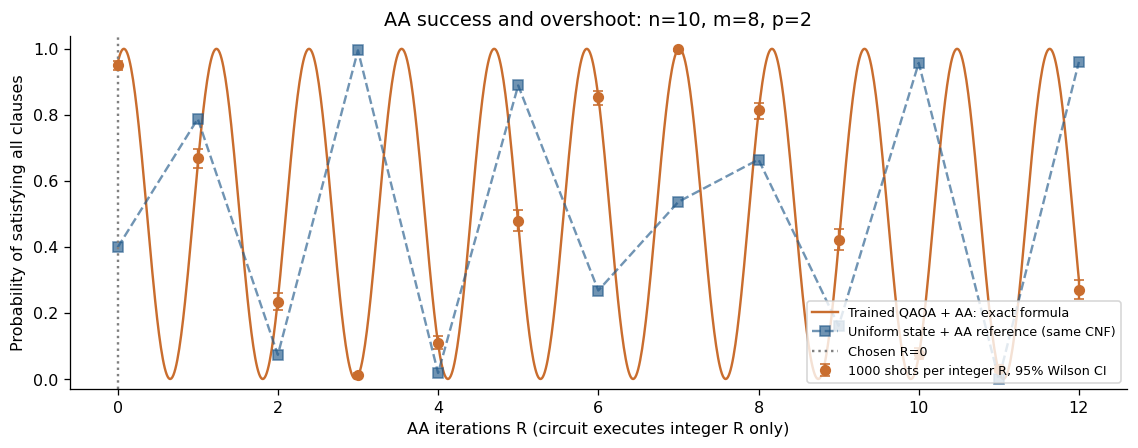

In [14]:
r_grid=np.arange(AA_R_MAX+1)
aa_curve=[]
for r in r_grid:
    state_r=amplify(psi,good,int(r))
    counts_r=sample_state(state_r,SHOTS,np.random.default_rng(SHOT_SEED+100+int(r)))
    successes=int(counts_r[good].sum())
    lo,hi=wilson_interval(successes,SHOTS)
    aa_curve.append({'R':int(r),'P_exact':float(aa_probability(P0,r)),
                     'SAT_shots':successes,'shots':SHOTS,'P_estimate':successes/SHOTS,'CI_low':lo,'CI_high':hi})
write_csv('AA_success_vs_R.csv',aa_curve)
fig,ax=plt.subplots(figsize=(10,4))
continuous_r=np.linspace(0,AA_R_MAX,1000)
ax.plot(continuous_r,aa_probability(P0,continuous_r),color=COLORS['QAOA+AA'],label='Trained QAOA + AA: exact formula')
y=np.array([row['P_estimate'] for row in aa_curve])
error=np.array([[row['P_estimate']-row['CI_low'] for row in aa_curve],[row['CI_high']-row['P_estimate'] for row in aa_curve]])
error=np.maximum(error,0)
ax.errorbar(r_grid,y,yerr=error,fmt='o',color=COLORS['QAOA+AA'],capsize=3,label='1000 shots per integer R, 95% Wilson CI')
ax.plot(r_grid,aa_probability(float(good.mean()),r_grid),'s--',color=COLORS['QAOA'],alpha=.65,label='Uniform state + AA reference (same CNF)')
ax.axvline(R_FIXED,color='gray',linestyle=':',label=f'Chosen R={R_FIXED}')
ax.set(xlabel='AA iterations R (circuit executes integer R only)',ylabel='Probability of satisfying all clauses',ylim=(-.03,1.04),title=f'AA success and overshoot: n={N}, m={M}, p={P_SELECTED}')
ax.legend(fontsize=8,loc='lower right'); fig.tight_layout(); save_figure(fig,'07_AA_success_probability')

## 6. 1000-shot 结果、Sparrow 统计与输出解概率

量子固定电路各使用 1000 个输出；Sparrow 用 1000 个不同种子的完整求解进程。仅比较 QAOA、固定轮数 QAOA+AA 和 Sparrow，分别报告精确成功概率与采样频率。

本次固定最优 R=0，两种固定电路分布完全相同；945/1000 与 963/1000 的频率差异来自独立有限-shot 采样，不能解读成 AA 改善了成功率。

In [15]:
q_counts=sample_state(psi,SHOTS,np.random.default_rng(SHOT_SEED))
aa_counts=sample_state(psi_aa,SHOTS,np.random.default_rng(SHOT_SEED+1))
sparrow_batch=run_sparrow_batch(N,clauses,seeds=range(1,SPARROW_RUNS+1),exe_path=SPARROW_EXE,
                               maxflips=SPARROW_MAXFLIPS,wall_timeout_s=5)
sparrow_counts=np.zeros(1<<N,dtype=np.int64)
for result in sparrow_batch['results']:
    if result['status']=='SAT': sparrow_counts[result['model_int']]+=1
accuracy=[]
for label,successes,denominator,unit,measurements in [
    ('QAOA',int(q_counts[good].sum()),SHOTS,'one measured circuit',SHOTS),
    ('QAOA+AA',int(aa_counts[good].sum()),SHOTS,'one measured fixed-R circuit',SHOTS),
    ('Sparrow',sparrow_batch['num_sat'],SPARROW_RUNS,'one native solver run',SPARROW_RUNS)]:
    lo,hi=wilson_interval(successes,denominator)
    accuracy.append({'method':label,'SAT_outputs':successes,'trials_or_shots':denominator,'trial_unit':unit,
                     'SAT_rate':successes/denominator,'CI_low':lo,'CI_high':hi,'measurements_or_calls':measurements})
show_table(accuracy); write_csv('success_accuracy.csv',accuracy)
write_csv('sparrow_runs.csv',[{key:result[key] for key in ['seed','status','model_bitstring','model_valid','wall_time_s','cpu_time_s','total_flips','exit_code']}
                              for result in sparrow_batch['results']])

prob_q=np.abs(psi)**2; prob_aa=np.abs(psi_aa)**2
probability_rows=[]
for x in range(1<<N):
    probability_rows.append({'state':bitstring(x,N),'state_index':x,'is_SAT':bool(good[x]),'cost_H_C':int(cost_diagonal[x]),'violated_clauses':int(violations[x]),
      'QAOA_probability_exact':float(prob_q[x]),'QAOA_count':int(q_counts[x]),'QAOA_frequency':q_counts[x]/SHOTS,
      'AA_probability_exact':float(prob_aa[x]),'AA_count':int(aa_counts[x]),'AA_frequency':aa_counts[x]/SHOTS,
      'Sparrow_count':int(sparrow_counts[x]),'Sparrow_empirical_frequency':sparrow_counts[x]/SPARROW_RUNS,
      'QAOA_amplitude_real':float(psi[x].real),'QAOA_amplitude_imag':float(psi[x].imag),'QAOA_amplitude_abs':float(abs(psi[x])),
      'QAOA_phase_rad':float(np.angle(psi[x])),'AA_amplitude_abs':float(abs(psi_aa[x])),'AA_phase_rad':float(np.angle(psi_aa[x]))})
write_csv('all_output_probabilities_and_amplitudes.csv',probability_rows)
print('All 1024 basis-state probabilities, shot counts and amplitudes are saved in CSV.')
show_table(sorted(probability_rows,key=lambda row:row['QAOA_probability_exact'],reverse=True),limit=12)
for label,counts in [('QAOA',q_counts),('QAOA+AA',aa_counts),('Sparrow',sparrow_counts)]:
    x=int(np.argmax(counts))
    print(f'{label}: most frequent output={bitstring(x,N)}, count={counts[x]}, SAT={good[x]}, original bits={[int((x>>i)&1) for i in range(N)]}')
print('Sparrow and quantum outputs may differ; every satisfying assignment is a correct solution.')

method,SAT_outputs,trials_or_shots,trial_unit,SAT_rate,CI_low,CI_high,measurements_or_calls
QAOA,945,1000,one measured circuit,0.945,0.9290916123226243,0.9575025726252315,1000
QAOA+AA,963,1000,one measured fixed-R circuit,0.963,0.9494176025179306,0.9730388191244452,1000
Sparrow,1000,1000,one native solver run,1.0,0.996173241514445,1.0,1000


All 1024 basis-state probabilities, shot counts and amplitudes are saved in CSV.


state,state_index,is_SAT,cost_H_C,violated_clauses,QAOA_probability_exact,QAOA_count,QAOA_frequency,AA_probability_exact,AA_count,AA_frequency,Sparrow_count,Sparrow_empirical_frequency,QAOA_amplitude_real,QAOA_amplitude_imag,QAOA_amplitude_abs,QAOA_phase_rad,AA_amplitude_abs,AA_phase_rad
1111000111,967,True,-8,0,0.004587549838197555,4,0.004,0.004587549838197555,5,0.005,6,0.006,-0.06364363945134878,-0.023174058677415073,0.06773145383200892,-2.792392666900883,0.06773145383200892,-2.792392666900883
1111000101,965,True,-8,0,0.004502695331194428,4,0.004,0.004502695331194428,3,0.003,7,0.007,-0.05877655601633436,-0.032373010271723825,0.06710212613020862,-2.6381500246515017,0.06710212613020862,-2.6381500246515017
0101010011,339,True,-8,0,0.00443697789339873,4,0.004,0.00443697789339873,4,0.004,2,0.002,-0.05591885288148753,-0.03619474804190912,0.06661064399477556,-2.567137066717554,0.06661064399477556,-2.567137066717554
0001011100,92,True,-8,0,0.0044191825274516126,2,0.002,0.0044191825274516126,3,0.003,2,0.002,-0.05671286411198649,-0.03468189112010715,0.06647693229573408,-2.5927348114784343,0.06647693229573408,-2.5927348114784343
0100010011,275,True,-8,0,0.004241298777841335,2,0.002,0.004241298777841335,3,0.003,7,0.007,-0.0597616630616093,-0.025881313837439118,0.0651252545318737,-2.732901892763203,0.0651252545318737,-2.732901892763203
0000011100,28,True,-8,0,0.004098643541196582,7,0.007,0.004098643541196582,2,0.002,5,0.005,-0.0588696457356633,-0.025159657234431535,0.06402064933438728,-2.7377085993942973,0.06402064933438728,-2.7377085993942973
0101011000,344,True,-8,0,0.004096359198413233,3,0.003,0.004096359198413233,5,0.005,4,0.004,-0.056565943001969925,-0.029944169561220466,0.06400280617608288,-2.6547280280938295,0.06400280617608288,-2.6547280280938295
1111101100,1004,True,-8,0,0.004043525359419128,8,0.008,0.004043525359419128,4,0.004,3,0.003,-0.054238492279090805,-0.03319203691716035,0.06358872037884651,-2.5924220747117204,0.06358872037884651,-2.5924220747117204
1111100110,998,True,-8,0,0.003947532741854487,4,0.004,0.003947532741854487,9,0.009,4,0.004,-0.052993634615407216,-0.03375214707397442,0.06282939393193672,-2.5744750358857766,0.06282939393193672,-2.5744750358857766
0100011000,280,True,-8,0,0.00394666710398398,4,0.004,0.00394666710398398,4,0.004,10,0.01,-0.059551243040611934,-0.02000791234241965,0.06282250475732387,-2.817463718081197,0.06282250475732387,-2.817463718081197


QAOA: most frequent output=0001000001, count=8, SAT=True, original bits=[1, 0, 0, 0, 0, 0, 1, 0, 0, 0]
QAOA+AA: most frequent output=0001000001, count=9, SAT=True, original bits=[1, 0, 0, 0, 0, 0, 1, 0, 0, 0]
Sparrow: most frequent output=0101010001, count=12, SAT=True, original bits=[1, 0, 0, 0, 1, 0, 1, 0, 1, 0]
Sparrow and quantum outputs may differ; every satisfying assignment is a correct solution.


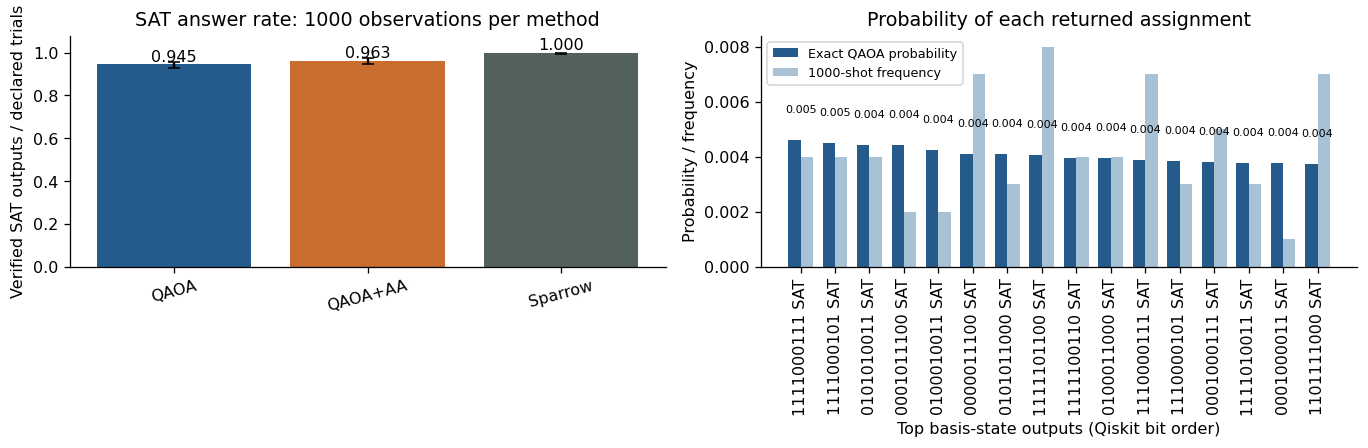

In [16]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
labels=[row['method'] for row in accuracy]
y=np.array([row['SAT_rate'] for row in accuracy])
yerr=np.array([[row['SAT_rate']-row['CI_low'] for row in accuracy],[row['CI_high']-row['SAT_rate'] for row in accuracy]])
yerr=np.maximum(yerr,0)
axes[0].bar(labels,y,color=[COLORS[label] for label in labels],yerr=yerr,capsize=4)
for i,value in enumerate(y): axes[0].text(i,min(1.035,value+.016),f'{value:.3f}',ha='center')
axes[0].set(ylabel='Verified SAT outputs / declared trials',ylim=(0,1.08),title='SAT answer rate: 1000 observations per method')
axes[0].tick_params(axis='x',labelrotation=15)
top=np.argsort(prob_q)[-16:][::-1]
axes[1].bar(np.arange(len(top))-.18,prob_q[top],width=.36,color=COLORS['QAOA'],label='Exact QAOA probability')
axes[1].bar(np.arange(len(top))+.18,q_counts[top]/SHOTS,width=.36,color='#a8c1d4',label='1000-shot frequency')
for i,x in enumerate(top): axes[1].text(i,prob_q[x]+.001,f'{prob_q[x]:.3f}',ha='center',fontsize=7)
axes[1].set(xticks=np.arange(len(top)),xticklabels=[bitstring(x,N)+(' SAT' if good[x] else ' fail') for x in top],
            xlabel='Top basis-state outputs (Qiskit bit order)',ylabel='Probability / frequency',title='Probability of each returned assignment')
axes[1].tick_params(axis='x',labelrotation=90); axes[1].legend(fontsize=8)
fig.tight_layout(); save_figure(fig,'09_accuracy_and_output_probabilities')

## 7. Amplitude spectrum：把解按真实振幅排出来

振幅 $\alpha_x$ 是复数，图里显示它的大小 $|\alpha_x|$。测到这个比特串的概率是

$$P(x)=|\alpha_x|^2.$$

左图按振幅从高到低展示前 12 个状态，并加入**振幅最高的非解**作为灰色参照。右图保留全部 $2^{10}=1024$ 个状态，只改变横轴的排列顺序，不改变任何振幅。

本次结果中，最大振幅对应 `1111000111`，它满足所有子句。它的振幅约为 $0.06773$，所以这**一个解**的输出概率约为 $0.459\%$。
全部 408 个解的概率加起来才是 $95.6\%$。有很多个正确答案，因此不应期待只有一个独立的大峰。

下面的程序独立检查哪些状态是解。本次训练结果恰好满足“所有解的振幅都高于所有非解”，这不是一般 QAOA 的保证。
选择的 $R=0$ 让 QAOA 和固定 AA 的分布相同。第二幅图另外展示 $R=1$，同时保留真实 Qiskit AA 电路与公式的核对。
1000 shots 只能估计概率；这里的精确振幅来自理想态矢量，复数实部、虚部及相位仍保存在完整 CSV 中。


### 单个解的振幅与全部解的概率

归一化要求 $\sum_x|\alpha_x|^2=1$。本实例有 408 个满足解，应考察
$P_{\rm SAT}=\sum_{x\in\mathrm{SAT}}|\alpha_x|^2$，而不是要求每一个解的振幅接近 1。
若概率全部均匀集中于这 408 个解，每个解的振幅也只有 $1/\sqrt{408}\approx0.0495$。

本次全部满足解的概率总和约 **95.59%**，最大单个解的振幅约 **0.06773**，
其概率约 **0.459%**。初始 1024 态均匀叠加中每个态的振幅为 $1/\sqrt{1024}=0.03125$。
AA 改变满足解子空间的总概率，并保留该子空间内部各解的相对比例，
不会自动把概率集中到某一个指定解上。


Largest amplitude: 1111000111, SAT=True, |alpha|=0.06773145, individual P=0.459%
Total SAT probability across 408 answers: 95.587%
Top 20 are SAT: True. Minimum SAT amplitude=0.03290; maximum non-SAT amplitude=0.02879.
SAT amplitudes all exceed non-SAT amplitudes in this run: True


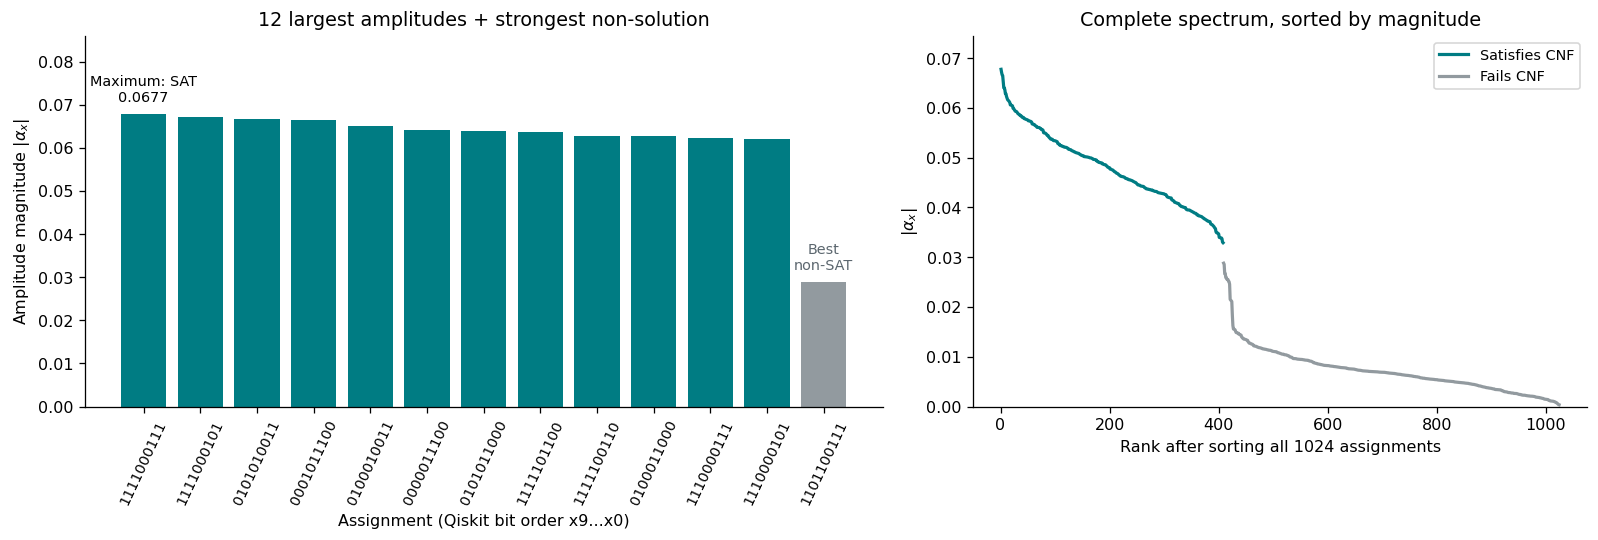

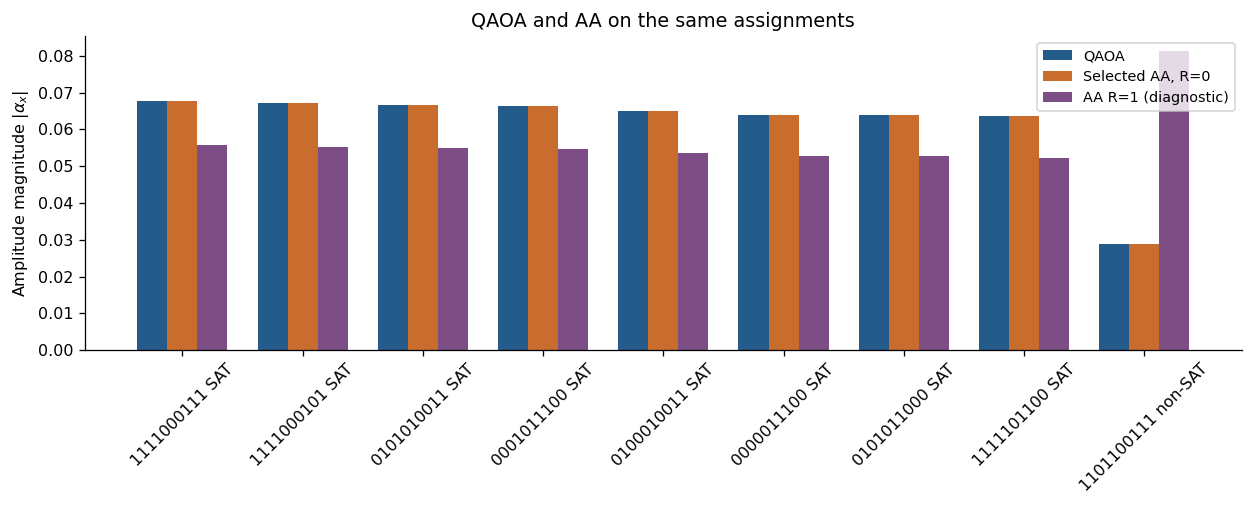

In [17]:
# Keep a nonzero-AA circuit check even though the chosen first-peak R is zero.
psi_one=Statevector.from_instruction(aa_circuit(N,clauses,gammas,betas,good,1)).data
assert Statevector(psi_one).equiv(Statevector(amplify(psi,good,1)))
assert np.isclose(np.sum(np.abs(psi_one[good])**2),aa_probability(P0,1),atol=1e-10)
amplitudes=np.abs(psi)
ranked=np.argsort(-amplitudes,kind='stable')
top=ranked[:12]
best_fail=int(np.flatnonzero(~good)[np.argmax(amplitudes[~good])])
shown=np.r_[top,best_fail] if best_fail not in top else top
largest=int(ranked[0])
min_sat=float(amplitudes[good].min()); max_fail=float(amplitudes[~good].max())
print(f'Largest amplitude: {bitstring(largest,N)}, SAT={bool(good[largest])}, '
      f'|alpha|={amplitudes[largest]:.8f}, individual P={100*amplitudes[largest]**2:.3f}%')
print(f'Total SAT probability across {int(good.sum())} answers: {100*P0:.3f}%')
print(f'Top 20 are SAT: {bool(np.all(good[ranked[:20]]))}. '
      f'Minimum SAT amplitude={min_sat:.5f}; maximum non-SAT amplitude={max_fail:.5f}.')
print('SAT amplitudes all exceed non-SAT amplitudes in this run:',min_sat>max_fail)

rank_rows=[{'rank_by_QAOA_magnitude':rank,'state':bitstring(int(x),N),'state_index':int(x),
            'is_SAT':bool(good[x]),'QAOA_amplitude_abs':float(amplitudes[x]),
            'QAOA_probability_exact':float(amplitudes[x]**2),
            'AA_selected_amplitude_abs':float(abs(psi_aa[x])),
            'AA_R1_amplitude_abs':float(abs(psi_one[x]))}
           for rank,x in enumerate(ranked,1)]
write_csv('ranked_amplitudes.csv',rank_rows)
fig,axes=plt.subplots(1,2,figsize=(14,4.8),gridspec_kw={'width_ratios':[1.3,1]})
colors=['#007c83' if good[x] else '#929a9f' for x in shown]
axes[0].bar(np.arange(len(shown)),amplitudes[shown],color=colors)
axes[0].set(xticks=np.arange(len(shown)),xticklabels=[bitstring(int(x),N) for x in shown],
            ylabel=r'Amplitude magnitude $|\alpha_x|$',ylim=(0,float(amplitudes.max())*1.27),
            title='12 largest amplitudes + strongest non-solution')
axes[0].tick_params(axis='x',labelrotation=65,labelsize=9)
axes[0].set_xlabel('Assignment (Qiskit bit order x9...x0)')
axes[0].text(0,amplitudes[largest]+.003,f'Maximum: SAT\n{amplitudes[largest]:.4f}',ha='center',fontsize=9)
if best_fail not in top:
    axes[0].text(len(shown)-1,max_fail+.003,'Best\nnon-SAT',ha='center',fontsize=9,color='#5c676f')
for mask,color,label in [(good,'#007c83','Satisfies CNF'),(~good,'#929a9f','Fails CNF')]:
    y=np.where(mask[ranked],amplitudes[ranked],np.nan)
    axes[1].plot(np.arange(1,len(ranked)+1),y,color=color,linewidth=2,label=label)
axes[1].set(xlabel='Rank after sorting all 1024 assignments',ylabel=r'$|\alpha_x|$',
            title='Complete spectrum, sorted by magnitude',ylim=(0,float(amplitudes.max())*1.1))
axes[1].legend(fontsize=9)
fig.tight_layout(); save_figure(fig,'10_amplitude_spectrum')

# A common set of labels makes the R=1 change visible without reordering the bars.
shown_small=np.r_[ranked[:8],best_fail]
fig,ax=plt.subplots(figsize=(11,4.5)); positions=np.arange(len(shown_small))
for offset,label,state,color in [(-.25,'QAOA',psi,COLORS['QAOA']),
    (0,f'Selected AA, R={R_FIXED}',psi_aa,COLORS['QAOA+AA']),
    (.25,'AA R=1 (diagnostic)',psi_one,'#7d4d86')]:
    ax.bar(positions+offset,np.abs(state[shown_small]),width=.25,label=label,color=color)
ax.set(xticks=positions,xticklabels=[bitstring(int(x),N)+(' SAT' if good[x] else ' non-SAT') for x in shown_small],
       ylabel=r'Amplitude magnitude $|\alpha_x|$',title='QAOA and AA on the same assignments')
ax.tick_params(axis='x',labelrotation=45); ax.legend(fontsize=9)
fig.tight_layout(); save_figure(fig,'10b_amplitude_QAOA_AA_comparison')


## 8. 每个电路区块的无纠错时间模型

从论文 Eq. (7) 只保留电路重复结构，**不使用** $n_P$、surface code 周期、T-state factory 或 TACU 容错时间。
令 $t_A$ 包含初始 H 和 p 层 phaser/mixer，$t_C,t_0$ 包含两个可逆 oracle 的门时间，则

$$t_R=t_{\rm reset}+t_A+R(2t_A+t_C+t_0)+t_{\rm measure}.$$

这明确计入了第一遍状态制备。训练成本在 CPU 上单独记录：

$$q_{99}=\left\lceil\frac{\log(1-0.99)}{\log(1-P_R)}\right\rceil,\qquad
T_{99}=t_{\rm pretrain}+q_{99}t_R.$$

假设的门模型把电路分解成 x/h/rx/rz/cx，以各比特空闲时间安排可并行的门；假设全连接。
50 ns 单比特门、300 ns CX、1 μs 测量/重置只是可改的示例参数，没有硬件校准来源。
硬件训练还需要有限-shot 期望值评估；本例的精确模拟训练时间不能替代真实量子硬件训练时间。

block,seconds_model
A: initial H + p phaser/mixer layers,1.720000000000001e-05
O_C: compute + phase + uncompute,5.465000000000021e-05
O_0: zero-state reflection,0.00010234999999999968
"Full one-shot circuit, R=0",1.9200000000000013e-05


method,pretrain_wall_s,one_shot_simulator_wall_s,P_exact,shots_for_99pct,cold_TTS99_simulator_s
QAOA,0.0773336999991443,0.008479000010993332,0.9558699561672634,2,0.09429170002113096
QAOA+AA,0.0773336999991443,0.008479000010993332,0.9558699561672634,2,0.09429170002113096
Sparrow,0,0.009597000000000001,1.0,1,0.009597000000000001


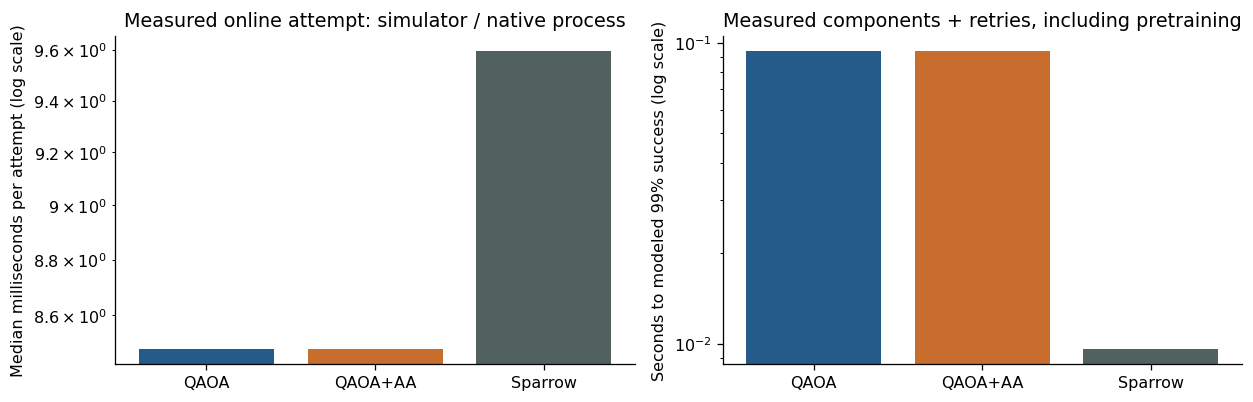

In [18]:
time_model=non_ft_time_model(N,clauses,gammas,betas,R_FIXED,SINGLE_QUBIT_S,CX_S,MEASURE_S,RESET_S)
time_blocks=[{'block':'A: initial H + p phaser/mixer layers','seconds_model':time_model['T_A_s']},
             {'block':'O_C: compute + phase + uncompute','seconds_model':time_model['T_OC_s']},
             {'block':'O_0: zero-state reflection','seconds_model':time_model['T_O0_s']},
             {'block':f'Full one-shot circuit, R={R_FIXED}','seconds_model':time_model['T_one_shot_s']}]
show_table(time_blocks); write_csv('illustrative_non_ft_gate_times.csv',time_blocks)
q_one=one_shot_simulator_time(qaoa_qc,good,np.random.default_rng(61),TIMING_REPEATS)
aa_one=q_one if R_FIXED==0 else one_shot_simulator_time(aa_qc,good,np.random.default_rng(62),TIMING_REPEATS)
main_times=[{'method':'QAOA','pretrain_wall_s':PRETRAIN_S,'one_shot_simulator_wall_s':q_one,
             'P_exact':P0,'shots_for_99pct':repetitions_for_target(P0,TARGET_SUCCESS),
             'cold_TTS99_simulator_s':PRETRAIN_S+repetitions_for_target(P0,TARGET_SUCCESS)*q_one},
            {'method':'QAOA+AA','pretrain_wall_s':PRETRAIN_S,'one_shot_simulator_wall_s':aa_one,
             'P_exact':P_AA,'shots_for_99pct':repetitions_for_target(P_AA,TARGET_SUCCESS),
             'cold_TTS99_simulator_s':PRETRAIN_S+repetitions_for_target(P_AA,TARGET_SUCCESS)*aa_one},
            {'method':'Sparrow','pretrain_wall_s':0,'one_shot_simulator_wall_s':sparrow_batch['median_wall_time_s'],
             'P_exact':sparrow_batch['success_rate'],'shots_for_99pct':repetitions_for_target(sparrow_batch['success_rate'],TARGET_SUCCESS),
             'cold_TTS99_simulator_s':repetitions_for_target(sparrow_batch['success_rate'],TARGET_SUCCESS)*sparrow_batch['median_wall_time_s']}]
show_table(main_times); write_csv('main_measured_time_comparison.csv',main_times)
fig,axes=plt.subplots(1,2,figsize=(11,3.6))
labels=[row['method'] for row in main_times]
axes[0].bar(labels,[row['one_shot_simulator_wall_s']*1000 for row in main_times],color=[COLORS[x] for x in labels])
axes[0].set(ylabel='Median milliseconds per attempt (log scale)',yscale='log',title='Measured online attempt: simulator / native process')
axes[1].bar(labels,[row['cold_TTS99_simulator_s'] for row in main_times],color=[COLORS[x] for x in labels])
axes[1].set(ylabel='Seconds to modeled 99% success (log scale)',yscale='log',title='Measured components + retries, including pretraining')
fig.tight_layout(); save_figure(fig,'11_measured_time_comparison')
print('WARNING: these are local classical execution measurements, not quantum hardware speed.')

## 9. 本机时间比较：Sparrow 为什么接近平的？

扫描 $n=6,8,10,12$，每个 $n$ 使用 3 个匹配的 SAT 实例，$m\approx0.8n$，固定 $p=2$。各实例均独立训练，量子方法计入多初值训练成本。
Sparrow 在每个扫描实例运行 500 次，每次返回的解都独立核验。**所有运行都成功了**。“没有 crossover”只表示曲线没有相交。

量子曲线是 **CPU 上 Qiskit 模拟器**重建状态并采样的耗时，加上预训练；Sparrow 曲线是完整原生进程的耗时，包含启动与输出传输。
按各自成功率换算独立重试后的 $T_{99}$ 是估计模型，并非计时到首次成功的第 99 百分位数。这些数据不能确定量子硬件的 crossover。

原扫描中 Sparrow 的四个中位数都约为 $9.7\,\mathrm{ms}$。这些小而稀疏的 CNF 很容易，进程启动与输出开销相对明显，搜索量随 $n$ 的变化在总时间中不明显。
图中增加一个纵轴放大的 Sparrow 视图，显示它有小幅波动。程序还单独进行 50 次 `--help` 和 50 次主 CNF 求解的交错检查，帮助判断启动开销的量级。
`--help` 包含帮助文本输出，和求解路径不同，因此只是启动/输出基线参照，**不把两者相减冒充精确搜索时间**。这次新检查与原扫描分别记录。
Sparrow 自报的 `0.000 s` 是精度有限的 CPU 统计，不能解释为真正零耗时。

本次扫描的第一峰选择全部为 $R=0$，因此 QAOA 和固定 QAOA+AA 两条曲线重合。
仅在已测范围内检查交点，不套用原论文随机 8-SAT 的时间指数，也不向大 $n$ 外推。


In [19]:
sweep_rows=[]
for n in SWEEP_N:
    m=max(1,int(round(M/N*n)))
    for instance in range(SWEEP_INSTANCES):
        seed=INSTANCE_SEED+1000*n+instance
        if n==N and instance==0: c,v,g=clauses,violations,good
        else: c,v,g,_=generate_sat_instance(n,m,seed)
        scan_cost=paper_cost_diagonal(n,c)
        learned=train_qaoa(n,scan_cost,g,P_SELECTED,TRAIN_SEED+seed,restarts=RESTARTS,maxiter=MAXITER)
        state=Statevector.from_instruction(qaoa_circuit(n,c,learned['gammas'],learned['betas'])).data
        success=float(np.abs(state[g])@np.abs(state[g]))
        r=choose_rounds(success)['best_first_peak']
        amplified=amplify(state,g,r); success_aa=float(np.abs(amplified[g])@np.abs(amplified[g]))
        q_circuit=qaoa_circuit(n,c,learned['gammas'],learned['betas'])
        aa_circuit_r=aa_circuit(n,c,learned['gammas'],learned['betas'],g,r)
        time_q=one_shot_simulator_time(q_circuit,g,np.random.default_rng(seed),TIMING_REPEATS)
        time_aa=time_q if r==0 else one_shot_simulator_time(aa_circuit_r,g,np.random.default_rng(seed+1),TIMING_REPEATS)
        classical=run_sparrow_batch(n,c,seeds=range(1,SWEEP_SPARROW_RUNS+1),exe_path=SPARROW_EXE,maxflips=SPARROW_MAXFLIPS)
        tts_c=classical['median_wall_time_s']*repetitions_for_target(classical['success_rate'],TARGET_SUCCESS)
        sweep_rows.append({'n':n,'m':m,'instance':instance,'seed':INSTANCE_SEED if n==N and instance==0 else seed,'training_seed':TRAIN_SEED+seed,'p':P_SELECTED,'R':r,
          'P_QAOA':success,'P_AA':success_aa,'Sparrow_SAT_rate':classical['success_rate'],
          'Sparrow_rate_CI_low':classical['success_rate_95pct_wilson'][0],
          'Sparrow_rate_CI_high':classical['success_rate_95pct_wilson'][1],
          'pretrain_s':learned['train_time_s'],'QAOA_online_attempt_s':time_q,'AA_online_attempt_s':time_aa,
          'Sparrow_process_attempt_s':classical['median_wall_time_s'],
          'QAOA_cold_TTS99_s':learned['train_time_s']+repetitions_for_target(success,TARGET_SUCCESS)*time_q,
          'AA_cold_TTS99_s':learned['train_time_s']+repetitions_for_target(success_aa,TARGET_SUCCESS)*time_aa,
          'Sparrow_TTS99_s':tts_c})
    print(f'Completed n={n}, m={m}: {SWEEP_INSTANCES} matched instances')
write_csv('crossover_all_instances.csv',sweep_rows)
crossover=[]
for n in SWEEP_N:
    subset=[row for row in sweep_rows if row['n']==n]
    crossover.append({'n':n,'m':subset[0]['m'],
       'QAOA':float(np.median([r['QAOA_cold_TTS99_s'] for r in subset])),
       'QAOA+AA':float(np.median([r['AA_cold_TTS99_s'] for r in subset])),
       'Sparrow':float(np.median([r['Sparrow_TTS99_s'] for r in subset]))})
write_csv('crossover_medians.csv',crossover); show_table(crossover)


Completed n=6, m=5: 3 matched instances


Completed n=8, m=6: 3 matched instances


Completed n=10, m=8: 3 matched instances


Completed n=12, m=10: 3 matched instances


n,m,QAOA,QAOA+AA,Sparrow
6,5,0.04563600002438761,0.04563600002438761,0.009666400000000002
8,6,0.09473490001983009,0.09473490001983009,0.00988255
10,8,0.10750139999436215,0.10750139999436215,0.00979755
12,10,0.25772270004381426,0.25772270004381426,0.009706900000000001


QAOA time-curve crossings: NONE in measured range (solver success is separate)
QAOA+AA time-curve crossings: NONE in measured range (solver success is separate)


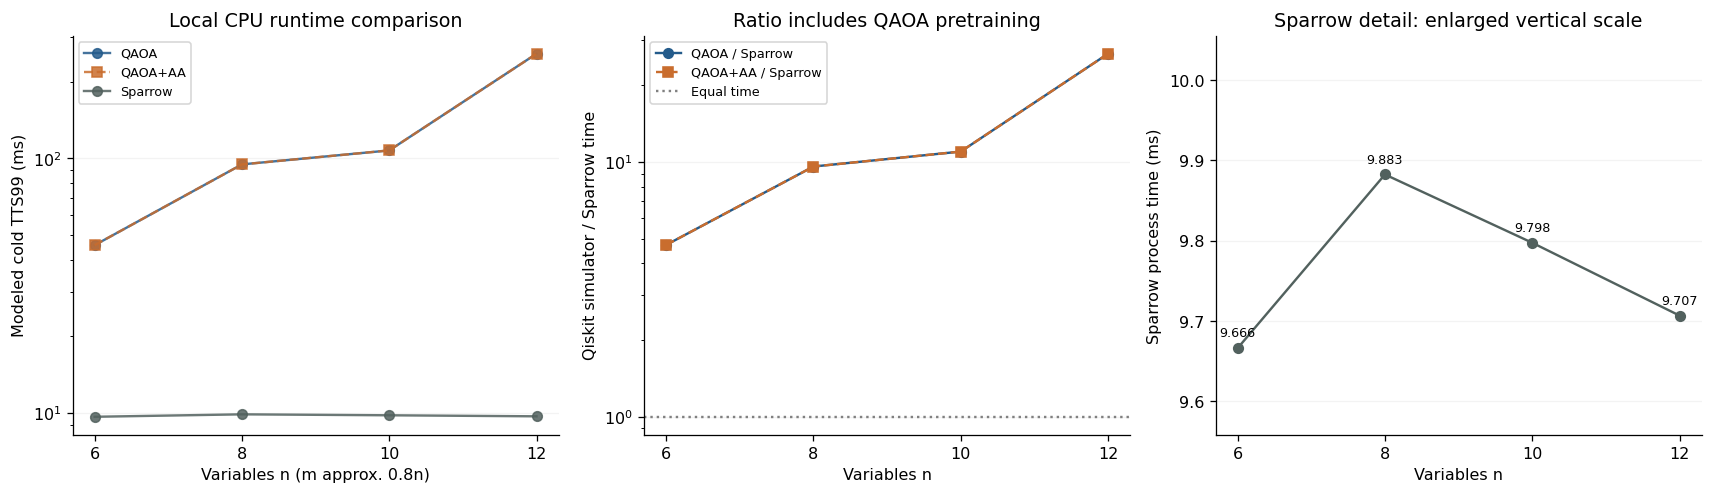

mode,runs,median_ms,q25_ms,q75_ms,measured_at
help_only,50,9.5749,9.216875000000002,9.933200000000001,2026-10-16T13:59:40.132668+08:00
solve_main_CNF,50,9.9326,9.478024999999999,10.306025000000002,2026-10-16T13:59:40.132789+08:00


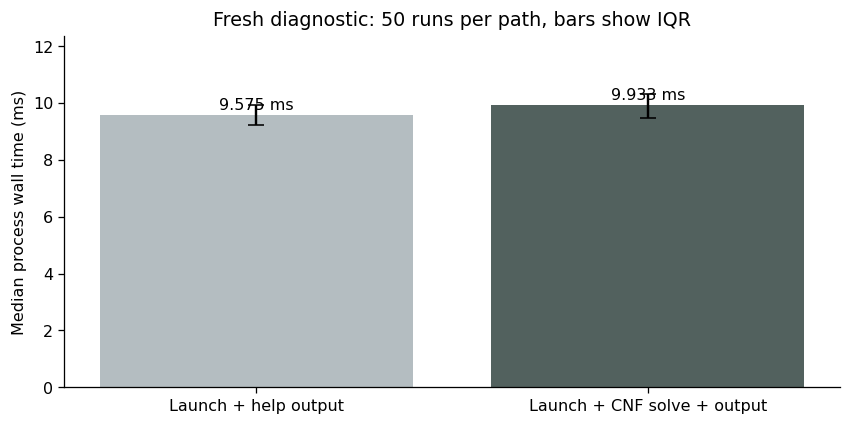

All 50 fresh CNF runs returned verified SAT models.
Help output is only an overhead reference. Do not subtract it as exact search time.


In [20]:
# Plot the measured scan. No extrapolation or fabricated crossover.
fig,axes=plt.subplots(1,3,figsize=(15,4.4))
x=np.array([row['n'] for row in crossover]); classical=np.array([row['Sparrow'] for row in crossover])
for method in ['QAOA','QAOA+AA','Sparrow']:
    y=np.array([row[method] for row in crossover])
    axes[0].plot(x,y*1000,'o-' if method!='QAOA+AA' else 's--',color=COLORS[method],label=method,alpha=.85)
for method in ['QAOA','QAOA+AA']:
    y=np.array([row[method] for row in crossover])
    axes[1].plot(x,y/classical,'o-' if method=='QAOA' else 's--',color=COLORS[method],label=method+' / Sparrow')
    roots=observed_crossings(x,y,classical)
    print(method,'time-curve crossings:',roots if roots else 'NONE in measured range (solver success is separate)')
axes[0].set(xlabel='Variables n (m approx. 0.8n)',ylabel='Modeled cold TTS99 (ms)',yscale='log',title='Local CPU runtime comparison')
axes[1].axhline(1,color='gray',linestyle=':',label='Equal time')
axes[1].set(xlabel='Variables n',ylabel='Qiskit simulator / Sparrow time',yscale='log',title='Ratio includes QAOA pretraining')
axes[2].plot(x,classical*1000,'o-',color=COLORS['Sparrow'])
for a,b in zip(x,classical*1000): axes[2].annotate(f'{b:.3f}',(a,b),xytext=(0,7),textcoords='offset points',ha='center',fontsize=8)
span=max(float(np.ptp(classical*1000)),.02)
axes[2].set(xlabel='Variables n',ylabel='Sparrow process time (ms)',title='Sparrow detail: enlarged vertical scale',
            ylim=(float(classical.min()*1000)-span*.5,float(classical.max()*1000)+span*.8))
for ax in axes:
    ax.set_xticks(x); ax.grid(axis='y',alpha=.15)
for ax in axes[:2]: ax.legend(fontsize=8)
fig.tight_layout(); save_figure(fig,'12_crossover_QAOA_AA_Sparrow')

# Separate fresh diagnostic: same executable and capture method, different paths.
import subprocess
from datetime import datetime
CHECK_REPEATS=50
calibration=[]
for rep in range(CHECK_REPEATS+3):
    for mode in (['help_only','solve_main_CNF'] if rep%2==0 else ['solve_main_CNF','help_only']):
        if mode=='help_only':
            start=time.perf_counter_ns()
            proc=subprocess.run([str(SPARROW_EXE),'--help'],capture_output=True,text=True,
                                encoding='utf-8',errors='replace',timeout=5,check=False)
            elapsed=(time.perf_counter_ns()-start)*1e-9
            status='HELP'; exit_code=proc.returncode
            assert exit_code==0 and 'Usage' in proc.stdout
        else:
            result=run_sparrow(N,clauses,seed=10001+rep,exe_path=SPARROW_EXE,maxflips=SPARROW_MAXFLIPS)
            elapsed=result['wall_time_s']; status=result['status']; exit_code=result['exit_code']
            assert status=='SAT' and result['model_valid']
        if rep>=3:
            calibration.append({'mode':mode,'repetition':rep-2,'wall_time_s':elapsed,
                                'status':status,'exit_code':exit_code})
write_csv('sparrow_startup_check.csv',calibration)
cal_summary=[]
for mode in ['help_only','solve_main_CNF']:
    values=np.array([row['wall_time_s']*1000 for row in calibration if row['mode']==mode])
    cal_summary.append({'mode':mode,'runs':len(values),'median_ms':float(np.median(values)),
                        'q25_ms':float(np.quantile(values,.25)),'q75_ms':float(np.quantile(values,.75)),
                        'measured_at':datetime.now().astimezone().isoformat()})
write_csv('sparrow_startup_check_summary.csv',cal_summary); show_table(cal_summary)
fig,ax=plt.subplots(figsize=(7.5,3.8))
med=np.array([r['median_ms'] for r in cal_summary])
err=np.array([med-[r['q25_ms'] for r in cal_summary],[r['q75_ms'] for r in cal_summary]-med])
ax.bar(['Launch + help output','Launch + CNF solve + output'],med,color=['#b4bdc1',COLORS['Sparrow']],yerr=err,capsize=5)
for i,v in enumerate(med): ax.text(i,v+.2,f'{v:.3f} ms',ha='center')
ax.set(ylabel='Median process wall time (ms)',title='Fresh diagnostic: 50 runs per path, bars show IQR',ylim=(0,float(max(r['q75_ms'] for r in cal_summary))*1.2))
fig.tight_layout(); save_figure(fig,'13_sparrow_startup_check')
print('All 50 fresh CNF runs returned verified SAT models.')
print('Help output is only an overhead reference. Do not subtract it as exact search time.')


## 10. 保存、复查与下一步

- `results/figures/`：电路图、训练、AA 成功率、输出概率、振幅谱、耗时与 crossover，PNG/PDF 两种格式。
- `results/data/`：完整逐状态概率、1000-shot 计数、Sparrow 每次模型/计时、训练参数与收敛记录、crossover 的每个实例。
- `data/`：三种方法共用的 DIMACS CNF。
- `notes/direct_sat_derivation.md`：直接 SAT 成本与相位门推导；`notes/theory_review.md`：公式约定、AA 与固定轮数选择的核对说明。

需要注意：
1. 原论文是随机 8-SAT、大 n、容错资源分析；本 Notebook 是 3-SAT 小实例的理想算法验证。
2. QAOA 使用 10 个数据比特；可逆 SAT oracle 使用 8 个归零的工作 flags。
3. 本机 Sparrow 2014 并未确认与论文实验的版本一致；平台随机数与计时也不同。
4. 最优 R=0 是有效结果。这个 n=10,m=8 的稀疏 SAT 往往有很多解，不能为展示 AA 而强行多放大。
5. 本机曲线没有交点，Sparrow 仍然成功求解；本机模拟图或假设门时间不能证明量子硬件优势。

公式来源：
- [原论文 v1](https://arxiv.org/abs/2504.01897v1)：Eqs. (2)–(5) QAOA；Eq. (6) AA 模块；Eq. (7) 重复模块计时结构。
- [Brassard et al.](https://arxiv.org/abs/quant-ph/0005055)：Eq. (1) 完整状态制备 A 的 AA；Eq. (5) $\sin^2\theta=P$；Eq. (8) 放大态与成功率；Theorem 3 未知 P 的 QSearch。
- [Qiskit Statevector 官方文档](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Statevector)：理想电路态矢量与测量概率。
- [SciPy minimize 官方文档](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)：L-BFGS-B 优化接口。

In [21]:
summary={'cost_definition':'paper_v1_Eq4_negative_satisfied_clauses','expected_cost':fit['expected_cost'],'n':N,'m':M,'p':P_SELECTED,'shots_per_fixed_circuit':SHOTS,'R_fixed':R_FIXED,
         'P_QAOA_exact':P0,'P_AA_exact':P_AA,'QAOA_SAT_shots':int(q_counts[good].sum()),
         'AA_SAT_shots':int(aa_counts[good].sum()),
         'Sparrow_runs':SPARROW_RUNS,'Sparrow_SAT_runs':sparrow_batch['num_sat'],
         'main_pretrain_s':PRETRAIN_S,'python':sys.version.split()[0],'qiskit':qiskit.__version__,
         'numpy':np.__version__,'scipy':scipy.__version__,
         'clause_view_max_error':clause_view_error,
         'circuit_view_max_error':circuit_view_error}
write_csv('experiment_summary.csv',[summary]); show_table([summary])
assert int(q_counts.sum())==1000 and int(aa_counts.sum())==1000
assert np.allclose(np.sum(np.abs(psi)**2),1) and np.allclose(np.sum(np.abs(psi_aa)**2),1)
assert np.all(np.asarray(aa_counts)>=0)
print('Completed. Figures:',FIGURES,'; CSV:',TABLES)

cost_definition,expected_cost,n,m,p,shots_per_fixed_circuit,R_fixed,P_QAOA_exact,P_AA_exact,QAOA_SAT_shots,AA_SAT_shots,Sparrow_runs,Sparrow_SAT_runs,main_pretrain_s,python,qiskit,numpy,scipy,clause_view_max_error,circuit_view_max_error
paper_v1_Eq4_negative_satisfied_clauses,-7.946089711033137,10,8,2,1000,0,0.9558699561672634,0.9558699561672634,945,963,1000,1000,0.0773336999991443,3.14.2,2.3.0,2.4.2,1.17.0,1.7554167342883506e-16,1.1364755910069911e-16


Completed. Figures: D:\桌面\hkust\urop\code\qaoa_aa_3sat\results\figures ; CSV: D:\桌面\hkust\urop\code\qaoa_aa_3sat\results\data
